# Real Estate Sales — ETL & Data Quality Analysis

## Objetivo

Preparar y validar los datos utilizados en el análisis de ventas inmobiliarias.

El proceso incluye:

- carga y exploración inicial de los datasets;
- validación de tipos de datos;
- análisis de valores nulos y duplicados;
- validación de claves primarias y foráneas;
- detección de inconsistencias;
- revisión de valores atípicos;
- transformación de variables;
- validación del modelo de datos;
- análisis exploratorio inicial.

El resultado será un conjunto de datos limpio y consistente que servirá como fuente para el dashboard interactivo.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [33]:
clientes = pd.read_csv("../public/data/dim_clientes.csv")

propiedades = pd.read_csv(
    "../public/data/dim_propiedades.csv"
)

ventas = pd.read_csv(
    "../public/data/hechos_ventas_propiedades.csv"
)

In [34]:
print("Clientes:", clientes.shape)
print("Propiedades:", propiedades.shape)
print("Ventas:", ventas.shape)

Clientes: (3500, 4)
Propiedades: (8000, 8)
Ventas: (8500, 10)


4. Inspección inicial

In [35]:
def resumen_dataset(df, nombre):
    print(f"\n{'=' * 50}")
    print(nombre)
    print(f"{'=' * 50}")

    print("\nDimensiones:")
    print(df.shape)

    print("\nTipos de datos:")
    print(df.dtypes)

    print("\nValores nulos:")
    print(df.isna().sum())

    print("\nDuplicados:")
    print(df.duplicated().sum())

    print("\nPrimeros registros:")
    display(df.head())

In [36]:
resumen_dataset(clientes, "DIM CLIENTES")
resumen_dataset(propiedades, "DIM PROPIEDADES")
resumen_dataset(ventas, "HECHOS VENTAS")


DIM CLIENTES

Dimensiones:
(3500, 4)

Tipos de datos:
id_cliente            object
segmento_comprador    object
pais                  object
ciudad                object
dtype: object

Valores nulos:
id_cliente            0
segmento_comprador    0
pais                  0
ciudad                0
dtype: int64

Duplicados:
0

Primeros registros:


,id_cliente,segmento_comprador,pais,ciudad
0,CUST00001,Primera vez,Colombia,Bogotá
1,CUST00002,Alto patrimonio,Mexico,Ciudad de México
2,CUST00003,Inversionista,Mexico,Ciudad de México
3,CUST00004,Inversionista,Colombia,Bogotá
4,CUST00005,Primera vez,Mexico,Ciudad de México



DIM PROPIEDADES

Dimensiones:
(8000, 8)

Tipos de datos:
id_propiedad           object
tipo_propiedad         object
ciudad                 object
barrio                 object
habitaciones            int64
tamano_m2               int64
precio_publicado        int64
categoria_propiedad    object
dtype: object

Valores nulos:
id_propiedad           0
tipo_propiedad         0
ciudad                 0
barrio                 0
habitaciones           0
tamano_m2              0
precio_publicado       0
categoria_propiedad    0
dtype: int64

Duplicados:
0

Primeros registros:


,id_propiedad,tipo_propiedad,ciudad,barrio,habitaciones,tamano_m2,precio_publicado,categoria_propiedad
0,PROP00001,Departamento,Bogotá,Usaquén,2,79,322670,Residencial
1,PROP00002,Departamento,Bogotá,Chapinero,4,128,260263,Residencial
2,PROP00003,Departamento,Bogotá,La Candelaria,3,46,147053,Residencial
3,PROP00004,Departamento,Bogotá,Rosales,1,172,342540,Residencial
4,PROP00005,Comercial,Bogotá,Rosales,0,303,1272336,Comercial



HECHOS VENTAS

Dimensiones:
(8500, 10)

Tipos de datos:
id_venta                object
fecha_venta             object
id_cliente              object
id_propiedad            object
ciudad                  object
precio_venta             int64
tipo_propiedad          object
canal_venta             object
porcentaje_comision    float64
monto_comision           int64
dtype: object

Valores nulos:
id_venta               0
fecha_venta            0
id_cliente             0
id_propiedad           0
ciudad                 0
precio_venta           0
tipo_propiedad         0
canal_venta            0
porcentaje_comision    0
monto_comision         0
dtype: int64

Duplicados:
0

Primeros registros:


,id_venta,fecha_venta,id_cliente,id_propiedad,ciudad,precio_venta,tipo_propiedad,canal_venta,porcentaje_comision,monto_comision
0,SALE000001,2024-01-05,CUST02497,PROP03591,Bogotá,1027126,Casa,Corredor,0.0473,48605
1,SALE000002,2024-06-16,CUST02903,PROP03005,Ciudad de México,233363,Departamento,Corredor,0.0458,10681
2,SALE000003,2024-10-13,CUST00831,PROP04661,Bogotá,209704,Departamento,Directo,0.0151,3156
3,SALE000004,2023-02-08,CUST01686,PROP06300,Bogotá,224411,Departamento,Corredor,0.0380,8523
4,SALE000005,2024-11-29,CUST00639,PROP00792,Ciudad de México,192007,Departamento,Directo,0.0159,3054


5. Validación de claves primarias

In [37]:
clientes["id_cliente"].duplicated().sum()

np.int64(0)

In [38]:
propiedades["id_propiedad"].duplicated().sum()

np.int64(0)

In [39]:
ventas["id_venta"].duplicated().sum()

np.int64(0)

### Validación de claves primarias

Se verificó que las claves principales de las tres tablas fueran únicas.

Esto permite utilizar:

- `id_cliente` como clave primaria de `dim_clientes`.
- `id_propiedad` como clave primaria de `dim_propiedades`.
- `id_venta` como clave primaria de `hechos_ventas_propiedades`.

6. Validar relaciones entre las tablas

In [40]:
clientes_invalidos = ventas[
    ~ventas["id_cliente"].isin(
        clientes["id_cliente"]
    )
]

len(clientes_invalidos)

0

In [41]:
propiedades_invalidas = ventas[
    ~ventas["id_propiedad"].isin(
        propiedades["id_propiedad"]
    )
]

len(propiedades_invalidas)

0

0, 0,  podremos afirmar que existe integridad referencial entre las tablas.

7. Conversión de tipos

ventas["fecha_venta"] = pd.to_datetime(
    ventas["fecha_venta"],
    errors="coerce"
)

In [42]:
ventas.dtypes

id_venta                object
fecha_venta             object
id_cliente              object
id_propiedad            object
ciudad                  object
precio_venta             int64
tipo_propiedad          object
canal_venta             object
porcentaje_comision    float64
monto_comision           int64
dtype: object

In [43]:
ventas["fecha_venta"].isna().sum()

np.int64(0)

verificar que las variables numéricas realmente sean numéricas:

In [44]:
columnas_numericas_ventas = [
    "precio_venta",
    "porcentaje_comision",
    "monto_comision"
]

ventas[columnas_numericas_ventas].describe()

,precio_venta,porcentaje_comision,monto_comision
count,8.500000e+03,8500.000000,8500.000000
mean,7.073532e+05,0.033233,23603.196000
std,6.458332e+05,0.012302,24988.696947
min,7.683700e+04,0.010000,1121.000000
25%,3.070042e+05,0.019200,8582.750000
50%,4.891235e+05,0.036300,15506.500000
75%,8.669085e+05,0.043300,28340.750000
max,4.944525e+06,0.050000,236423.000000


In [45]:
columnas_numericas_propiedades = [
    "habitaciones",
    "tamano_m2",
    "precio_publicado"
]

propiedades[
    columnas_numericas_propiedades
].describe()

,habitaciones,tamano_m2,precio_publicado
count,8000.000000,8000.000000,8.000000e+03
mean,2.339375,179.553500,7.608052e+05
std,1.366723,113.267421,6.901234e+05
min,0.000000,45.000000,8.554800e+04
25%,2.000000,99.000000,3.304380e+05
50%,2.000000,146.000000,5.266295e+05
75%,3.000000,232.000000,9.289555e+05
max,6.000000,599.000000,5.206092e+06


8. Una validación muy interesante: la comisión
Eso nos permite comprobar matemáticamente la calidad del dato.

In [46]:
ventas["comision_calculada"] = (
    ventas["precio_venta"]
    * ventas["porcentaje_comision"]
)

In [47]:
ventas["diferencia_comision"] = (
    ventas["monto_comision"]
    - ventas["comision_calculada"]
)

In [48]:
ventas[
    [
        "precio_venta",
        "porcentaje_comision",
        "monto_comision",
        "comision_calculada",
        "diferencia_comision"
    ]
].head()

,precio_venta,porcentaje_comision,monto_comision,comision_calculada,diferencia_comision
0,1027126,0.0473,48605,48583.0598,21.9402
1,233363,0.0458,10681,10688.0254,-7.0254
2,209704,0.0151,3156,3166.5304,-10.5304
3,224411,0.0380,8523,8527.6180,-4.6180
4,192007,0.0159,3054,3052.9113,1.0887


In [49]:
ventas["diferencia_comision"].abs().describe()

count    8.500000e+03
mean     1.751321e+01
std      2.124882e+01
min      4.547474e-13
25%      4.814075e+00
50%      1.082190e+01
75%      2.181860e+01
max      2.363600e+02
Name: diferencia_comision, dtype: float64

Esto es mucho más interesante que simplemente revisar nulos porque demuestra una regla de negocio:

monto_comision
≈
precio_venta × porcentaje_comision

9. Otra validación excelente: precio publicado vs precio de venta
Como tenemos:
dim_propiedades.precio_publicado

y:
ventas.precio_venta

podemos hacer un join:

In [50]:
ventas_propiedades = ventas.merge(
    propiedades[
        [
            "id_propiedad",
            "precio_publicado",
            "categoria_propiedad",
            "barrio"
        ]
    ],
    on="id_propiedad",
    how="left"
)

In [51]:
ventas_propiedades["diferencia_precio"] = (
    ventas_propiedades["precio_venta"]
    - ventas_propiedades["precio_publicado"]
)

In [52]:
ventas_propiedades["variacion_precio_pct"] = (
    ventas_propiedades["diferencia_precio"]
    / ventas_propiedades["precio_publicado"]
    * 100
)

Esto nos abre después un análisis bastante interesante:
¿Las propiedades generalmente se venden por encima o por debajo del precio publicado?

10. Hay una cuestión de normalización a revisar
La tabla `hechos_ventas_propiedades` contiene las columnas `ciudad` y
`tipo_propiedad`. Sin embargo, ambas variables también existen en
`dim_propiedades`.

Dado que `id_propiedad` permite relacionar ambas tablas, se evaluará si
estas columnas contienen la misma información.

El objetivo es:

1. Validar la consistencia entre la tabla de hechos y la dimensión.
2. Identificar atributos redundantes.
3. Evaluar si pueden eliminarse de la tabla de hechos para obtener un
   modelo dimensional más limpio.

Eso nos permite hacer una excelente comprobación:

In [53]:
validacion_propiedades = ventas.merge(
    propiedades[
        [
            "id_propiedad",
            "ciudad",
            "tipo_propiedad"
        ]
    ],
    on="id_propiedad",
    suffixes=("_venta", "_dimension")
)

In [54]:
(
    validacion_propiedades["ciudad_venta"]
    != validacion_propiedades["ciudad_dimension"]
).sum()

np.int64(0)

In [55]:
(
    validacion_propiedades["tipo_propiedad_venta"]
    != validacion_propiedades["tipo_propiedad_dimension"]
).sum()

np.int64(0)

Si ambas devuelven 0, confirmamos consistencia.

Pero también podremos explicar:
Para el modelo analítico final, las características descriptivas de la propiedad pueden obtenerse desde dim_propiedades mediante id_propiedad, reduciendo redundancia en la tabla de hechos.

Ahora hacemos el merge:

In [56]:
validacion_propiedades = ventas.merge(
    propiedades[
        [
            "id_propiedad",
            "ciudad",
            "tipo_propiedad"
        ]
    ],
    on="id_propiedad",
    how="left",
    suffixes=("_venta", "_dimension")
)

validacion_propiedades.head()

,id_venta,fecha_venta,id_cliente,id_propiedad,ciudad_venta,precio_venta,tipo_propiedad_venta,canal_venta,porcentaje_comision,monto_comision,comision_calculada,diferencia_comision,ciudad_dimension,tipo_propiedad_dimension
0,SALE000001,2024-01-05,CUST02497,PROP03591,Bogotá,1027126,Casa,Corredor,0.0473,48605,48583.0598,21.9402,Bogotá,Casa
1,SALE000002,2024-06-16,CUST02903,PROP03005,Ciudad de México,233363,Departamento,Corredor,0.0458,10681,10688.0254,-7.0254,Ciudad de México,Departamento
2,SALE000003,2024-10-13,CUST00831,PROP04661,Bogotá,209704,Departamento,Directo,0.0151,3156,3166.5304,-10.5304,Bogotá,Departamento
3,SALE000004,2023-02-08,CUST01686,PROP06300,Bogotá,224411,Departamento,Corredor,0.0380,8523,8527.6180,-4.6180,Bogotá,Departamento
4,SALE000005,2024-11-29,CUST00639,PROP00792,Ciudad de México,192007,Departamento,Directo,0.0159,3054,3052.9113,1.0887,Ciudad de México,Departamento


### Tasa de inconsistencia

Para cada registro se define:

$$
I_i =
\begin{cases}
1 & \text{si el valor de la tabla de hechos difiere de la dimensión} \\
0 & \text{si ambos valores coinciden}
\end{cases}
$$

La tasa de inconsistencia se calcula como:

$$
\text{Tasa de inconsistencia} =
\frac{\sum_{i=1}^{n} I_i}{n} \times 100
$$

In [57]:
validacion_propiedades["error_ciudad"] = (
    validacion_propiedades["ciudad_venta"]
    != validacion_propiedades["ciudad_dimension"]
)

validacion_propiedades["error_tipo_propiedad"] = (
    validacion_propiedades["tipo_propiedad_venta"]
    != validacion_propiedades["tipo_propiedad_dimension"]
)

In [58]:
errores_ciudad = (
    validacion_propiedades["error_ciudad"].sum()
)

errores_tipo = (
    validacion_propiedades["error_tipo_propiedad"].sum()
)

total_registros = len(validacion_propiedades)

tasa_error_ciudad = (
    errores_ciudad / total_registros * 100
)

tasa_error_tipo = (
    errores_tipo / total_registros * 100
)

print(
    f"Inconsistencias en ciudad: "
    f"{errores_ciudad} "
    f"({tasa_error_ciudad:.2f}%)"
)

print(
    f"Inconsistencias en tipo de propiedad: "
    f"{errores_tipo} "
    f"({tasa_error_tipo:.2f}%)"
)

Inconsistencias en ciudad: 0 (0.00%)
Inconsistencias en tipo de propiedad: 0 (0.00%)


### Interpretación

No se encontraron inconsistencias entre `ciudad` y `tipo_propiedad`
registrados en la tabla de ventas y los valores correspondientes en
`dim_propiedades`.

Esto indica que las columnas son consistentes, pero también confirma que
existe redundancia, ya que ambas características pueden recuperarse mediante
`id_propiedad`.

Por lo tanto, para el modelo analítico limpio, estas variables pueden
obtenerse directamente desde `dim_propiedades`.

Yo no modificaría los archivos originales. Mantendremos los CSV crudos intactos.

Creamos una nueva versión:

In [59]:
ventas_normalizadas = ventas.drop(
    columns=[
        "ciudad",
        "tipo_propiedad"
    ]
).copy()

ventas_normalizadas.head()

,id_venta,fecha_venta,id_cliente,id_propiedad,precio_venta,canal_venta,porcentaje_comision,monto_comision,comision_calculada,diferencia_comision
0,SALE000001,2024-01-05,CUST02497,PROP03591,1027126,Corredor,0.0473,48605,48583.0598,21.9402
1,SALE000002,2024-06-16,CUST02903,PROP03005,233363,Corredor,0.0458,10681,10688.0254,-7.0254
2,SALE000003,2024-10-13,CUST00831,PROP04661,209704,Directo,0.0151,3156,3166.5304,-10.5304
3,SALE000004,2023-02-08,CUST01686,PROP06300,224411,Corredor,0.0380,8523,8527.6180,-4.6180
4,SALE000005,2024-11-29,CUST00639,PROP00792,192007,Directo,0.0159,3054,3052.9113,1.0887


Ahora la tabla de hechos conceptualmente queda:
hechos_ventas_propiedades
│
├── id_venta
├── fecha_venta
├── id_cliente       → dim_clientes
├── id_propiedad     → dim_propiedades
├── precio_venta
├── porcentaje_comision
└── monto_comision

Y:
dim_propiedades
│
├── id_propiedad
├── tipo_propiedad
├── ciudad
├── barrio
├── habitaciones
├── tamano_m2
├── precio_publicado
└── categoria_propiedad

Mucho más limpio.

#11. Empezamos con las métricas matemáticas
Ahora sí podemos crear variables analíticas interesantes.

Yo empezaría con precio publicado vs precio de venta, porque tienes ambas variables y tiene mucho significado de negocio.

Primero unimos las ventas con la propiedad:

In [60]:
ventas_analisis = ventas_normalizadas.merge(
    propiedades,
    on="id_propiedad",
    how="left"
)

ventas_analisis.head()

,id_venta,fecha_venta,id_cliente,id_propiedad,precio_venta,canal_venta,porcentaje_comision,monto_comision,comision_calculada,diferencia_comision,tipo_propiedad,ciudad,barrio,habitaciones,tamano_m2,precio_publicado,categoria_propiedad
0,SALE000001,2024-01-05,CUST02497,PROP03591,1027126,Corredor,0.0473,48605,48583.0598,21.9402,Casa,Bogotá,Chicó,6,266,1075248,Residencial
1,SALE000002,2024-06-16,CUST02903,PROP03005,233363,Corredor,0.0458,10681,10688.0254,-7.0254,Departamento,Ciudad de México,Lomas de Chapultepec,3,96,248261,Residencial
2,SALE000003,2024-10-13,CUST00831,PROP04661,209704,Directo,0.0151,3156,3166.5304,-10.5304,Departamento,Bogotá,Chapinero,1,98,238246,Residencial
3,SALE000004,2023-02-08,CUST01686,PROP06300,224411,Corredor,0.0380,8523,8527.6180,-4.6180,Departamento,Bogotá,Zona T,3,79,229061,Residencial
4,SALE000005,2024-11-29,CUST00639,PROP00792,192007,Directo,0.0159,3054,3052.9113,1.0887,Departamento,Ciudad de México,Roma Norte,3,60,208029,Residencial


### Diferencia entre precio publicado y precio de venta

$$
D = P_v - P_p
$$

Donde:

- $P_v$ = precio de venta
- $P_p$ = precio publicado
- $D$ = diferencia entre ambos precios

Interpretación:

- $D > 0$: la propiedad se vendió por encima del precio publicado.
- $D = 0$: se vendió al precio publicado.
- $D < 0$: se vendió por debajo del precio publicado.

In [61]:
ventas_analisis["diferencia_precio"] = (
    ventas_analisis["precio_venta"]
    - ventas_analisis["precio_publicado"]
)

Puedes ver algunos registros:

In [62]:
ventas_analisis[
    [
        "id_venta",
        "precio_publicado",
        "precio_venta",
        "diferencia_precio"
    ]
].head(10)

,id_venta,precio_publicado,precio_venta,diferencia_precio
0,SALE000001,1075248,1027126,-48122
1,SALE000002,248261,233363,-14898
2,SALE000003,238246,209704,-28542
3,SALE000004,229061,224411,-4650
4,SALE000005,208029,192007,-16022
5,SALE000006,1418705,1329571,-89134
6,SALE000007,1000643,921185,-79458
7,SALE000008,785760,699350,-86410
8,SALE000009,1244233,1198695,-45538
9,SALE000010,590292,559747,-30545


### Variación porcentual del precio

Para poder comparar propiedades de diferentes precios se utiliza la
variación porcentual:

$$
\text{Variación \%} =
\frac{P_v-P_p}{P_p}\times100
$$

Interpretación:

- Valor positivo: venta por encima del precio publicado.
- Valor negativo: venta por debajo del precio publicado.
- Valor cercano a 0%: venta cercana al precio inicial.

In [64]:
ventas_analisis["variacion_precio_pct"] = (
    (
        ventas_analisis["precio_venta"]
        - ventas_analisis["precio_publicado"]
    )
    / ventas_analisis["precio_publicado"]
    * 100
)

In [65]:
ventas_analisis[
    [
        "precio_publicado",
        "precio_venta",
        "diferencia_precio",
        "variacion_precio_pct"
    ]
].head(10)

,precio_publicado,precio_venta,diferencia_precio,variacion_precio_pct
0,1075248,1027126,-48122,-4.475433
1,248261,233363,-14898,-6.000943
2,238246,209704,-28542,-11.980054
3,229061,224411,-4650,-2.030027
4,208029,192007,-16022,-7.701811
5,1418705,1329571,-89134,-6.282772
6,1000643,921185,-79458,-7.940694
7,785760,699350,-86410,-10.996997
8,1244233,1198695,-45538,-3.659925
9,590292,559747,-30545,-5.174558


### Precio de venta por metro cuadrado

$$
P_{m^2} =
\frac{P_v}{A}
$$

Donde:

- $P_v$ = precio de venta.
- $A$ = superficie de la propiedad en metros cuadrados.

Esta métrica permite comparar propiedades de tamaños diferentes utilizando
una unidad común.

In [66]:
ventas_analisis["precio_venta_m2"] = (
    ventas_analisis["precio_venta"]
    / ventas_analisis["tamano_m2"]
)

In [67]:
ventas_analisis[
    [
        "tipo_propiedad",
        "ciudad",
        "tamano_m2",
        "precio_venta",
        "precio_venta_m2"
    ]
].head()

,tipo_propiedad,ciudad,tamano_m2,precio_venta,precio_venta_m2
0,Casa,Bogotá,266,1027126,3861.375940
1,Departamento,Ciudad de México,96,233363,2430.864583
2,Departamento,Bogotá,98,209704,2139.836735
3,Departamento,Bogotá,79,224411,2840.645570
4,Departamento,Ciudad de México,60,192007,3200.116667


Esta variable después nos permitirá responder preguntas como:
¿Qué ciudad tiene mayor precio por m²?
¿Qué barrio es más caro?
¿Qué tipo de propiedad tiene mayor precio por m²?

11.4 Validación matemática de la comisión
Ya que tienes:
precio_venta
porcentaje_comision
monto_comision

podemos comprobar:
\[
C = P_v \times r
\]
donde:
- \(C\) = comisión
- \(P_v\) = precio de venta
- \(r\) = porcentaje de comisión en formato decimal
Por ejemplo:
\[
1,027,126 \times 0.0473
\approx 48,583
\]
Puede haber pequeñas diferencias por redondeo o por cómo se generaron los datos.

In [68]:
ventas_analisis["comision_calculada"] = (
    ventas_analisis["precio_venta"]
    * ventas_analisis["porcentaje_comision"]
)

In [69]:
ventas_analisis["error_comision"] = (
    ventas_analisis["monto_comision"]
    - ventas_analisis["comision_calculada"]
)

In [70]:
ventas_analisis[
    [
        "precio_venta",
        "porcentaje_comision",
        "monto_comision",
        "comision_calculada",
        "error_comision"
    ]
].head(10)

,precio_venta,porcentaje_comision,monto_comision,comision_calculada,error_comision
0,1027126,0.0473,48605,48583.0598,21.9402
1,233363,0.0458,10681,10688.0254,-7.0254
2,209704,0.0151,3156,3166.5304,-10.5304
3,224411,0.0380,8523,8527.6180,-4.6180
4,192007,0.0159,3054,3052.9113,1.0887
5,1329571,0.0155,20546,20608.3505,-62.3505
6,921185,0.0189,17382,17410.3965,-28.3965
7,699350,0.0495,34591,34617.8250,-26.8250
8,1198695,0.0193,23147,23134.8135,12.1865
9,559747,0.0177,9896,9907.5219,-11.5219


In [71]:
ventas_analisis["error_comision_abs"] = (
    ventas_analisis["error_comision"].abs()
)

In [72]:
ventas_analisis[
    "error_comision_abs"
].describe()

count    8.500000e+03
mean     1.751321e+01
std      2.124882e+01
min      4.547474e-13
25%      4.814075e+00
50%      1.082190e+01
75%      2.181860e+01
max      2.363600e+02
Name: error_comision_abs, dtype: float64

Esto nos permitirá decidir si las diferencias son simplemente redondeos o si existen errores de integridad.

11.5 Ratio precio de venta / precio publicado
Otra métrica que podemos crear es:
\[
R = \frac{P_v}{P_p}
\]

In [73]:
ventas_analisis["ratio_venta_publicado"] = (
    ventas_analisis["precio_venta"]
    / ventas_analisis["precio_publicado"]
)

Interpretación:
R > 1      venta superior al precio publicado
R = 1      venta al precio publicado
R < 1      venta inferior al precio publicado

Por ejemplo:
1.05 → aproximadamente 5% arriba
0.93 → aproximadamente 7% abajo

Esto es básicamente otra representación de nuestra variación porcentual:
\[
\text{Variación \%} = (R-1)\times100
\]

Las variables nuevas que ya tendremos
Después de estas celdas, ventas_analisis tendrá:
Variables originales
│
├── precio_venta
├── precio_publicado
├── tamano_m2
├── porcentaje_comision
├── monto_comision
│
▼
Variables derivadas
├── diferencia_precio
├── variacion_precio_pct
├── precio_venta_m2
├── comision_calculada
├── error_comision
├── error_comision_abs
└── ratio_venta_publicado

Y aquí empieza realmente la parte analítica interesante.

In [74]:
ventas_analisis[
    [
        "diferencia_precio",
        "variacion_precio_pct",
        "precio_venta_m2",
        "error_comision_abs"
    ]
].describe()

,diferencia_precio,variacion_precio_pct,precio_venta_m2,error_comision_abs
count,8500.000000,8500.000000,8500.000000,8.500000e+03
mean,-53411.086588,-7.058923,3656.770545,1.751321e+01
std,56330.429536,2.893818,1166.678628,2.124882e+01
min,-563112.000000,-11.999110,1608.049080,4.547474e-13
25%,-65014.500000,-9.608347,2807.298247,4.814075e+00
50%,-34935.000000,-7.035263,3554.150804,1.082190e+01
75%,-19623.250000,-4.575742,4297.702091,2.181860e+01
max,-2238.000000,-2.000147,8736.098000,2.363600e+02


Con esos valores podremos decidir correctamente qué técnica usar para detectar outliers: IQR, Z-score o una combinación, porque en datos inmobiliarios no deberíamos eliminar valores extremos simplemente porque sean grandes.

Hay un hallazgo bastante fuerte aquí:
diferencia_precio

mínimo:   -563,112
máximo:     -2,238

Incluso el máximo sigue siendo negativo.

Eso significa que:
\[
P_v < P_p
\]
para todas las operaciones.

Más importante aún, la variable porcentual nos dice:
variación mínima ≈ -12%
variación máxima ≈  -2%
media            ≈  -7.06%
mediana          ≈  -7.04%

Es decir, las propiedades parecen haberse vendido sistemáticamente con descuentos de aproximadamente 2% a 12% sobre el precio publicado.

### Interpretación inicial de las métricas derivadas

Las 8,500 ventas cuentan con información suficiente para calcular las
métricas derivadas.

Los primeros resultados muestran:

- Todas las propiedades se vendieron por debajo de su precio publicado.
- La reducción porcentual del precio se encuentra aproximadamente entre
  2% y 12%.
- El precio de venta por metro cuadrado presenta mayor dispersión que
  la variación porcentual del precio.
- Existen pequeñas diferencias entre la comisión registrada y la comisión
  recalculada, por lo que se evaluará si corresponden a errores reales o
  simplemente a precisión/redondeo del porcentaje de comisión.

Por ejemplo, una diferencia de:
-$500,000

puede parecer un outlier enorme, pero si la propiedad originalmente costaba varios millones, quizás solamente representa un descuento normal del 8%.

Por eso no eliminaría outliers basándonos todavía en diferencia_precio.

## 12. Detección de valores atípicos

Para identificar posibles valores atípicos se utilizará inicialmente
el método del rango intercuartílico (IQR).

$$
IQR = Q_3 - Q_1
$$

Los límites se calculan como:

$$
L_{inferior} = Q_1 - 1.5(IQR)
$$

$$
L_{superior} = Q_3 + 1.5(IQR)
$$

Los valores fuera de estos límites serán considerados **candidatos a
outlier**, pero no serán eliminados automáticamente.

En datos inmobiliarios, un valor extremo puede representar una propiedad
legítimamente costosa y no necesariamente un error.

In [75]:
def detectar_outliers_iqr(df, columna):
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df[
        (df[columna] < limite_inferior)
        |
        (df[columna] > limite_superior)
    ]

    return {
        "columna": columna,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "cantidad_outliers": len(outliers),
        "porcentaje_outliers": len(outliers) / len(df) * 100
    }

In [76]:
columnas_analisis = [
    "diferencia_precio",
    "variacion_precio_pct",
    "precio_venta_m2",
    "error_comision_abs"
]

resultados_outliers = pd.DataFrame(
    [
        detectar_outliers_iqr(
            ventas_analisis,
            columna
        )
        for columna in columnas_analisis
    ]
)

resultados_outliers

,columna,q1,q3,iqr,limite_inferior,limite_superior,cantidad_outliers,porcentaje_outliers
0,diferencia_precio,-65014.500000,-19623.250000,45391.250000,-133101.375000,48463.625000,673,7.917647
1,variacion_precio_pct,-9.608347,-4.575742,5.032605,-17.157254,2.973165,0,0.000000
2,precio_venta_m2,2807.298247,4297.702091,1490.403844,571.692481,6533.307858,216,2.541176
3,error_comision_abs,4.814075,21.818600,17.004525,-20.692712,47.325387,620,7.294118


Aunque existen diferencias absolutas de precio elevadas, la variación porcentual se mantiene dentro de un intervalo relativamente estable. [-12% : -2%]

13. Analizar precio_venta_m2
Aquí sí hay algo más interesante.

Tenemos:
media       3,656.77
mediana     3,554.15

Q1          2,807.30
Q3          4,297.70

máximo      8,736.10

La media está ligeramente por encima de la mediana:
\[
\bar{x} > Mediana
\]
lo que puede sugerir cierta asimetría hacia valores altos.

¿Los precios elevados por m² pertenecen a determinadas ciudades, barrios o tipos de propiedad?

In [77]:
ventas_analisis.nlargest(
    15,
    "precio_venta_m2"
)[
    [
        "ciudad",
        "barrio",
        "tipo_propiedad",
        "categoria_propiedad",
        "tamano_m2",
        "precio_venta",
        "precio_venta_m2"
    ]
]

,ciudad,barrio,tipo_propiedad,categoria_propiedad,tamano_m2,precio_venta,precio_venta_m2
6522,Ciudad de México,Polanco,Comercial,Comercial,500,4368049,8736.098000
8444,Ciudad de México,Roma Norte,Comercial,Comercial,335,2901663,8661.680597
5624,Ciudad de México,San Ángel,Comercial,Comercial,441,3772762,8555.015873
849,Ciudad de México,Condesa,Comercial,Comercial,364,3110876,8546.362637
3425,Ciudad de México,Lomas de Chapultepec,Comercial,Comercial,220,1879953,8545.240909
3760,Ciudad de México,Lomas de Chapultepec,Comercial,Comercial,137,1169296,8535.007299
2100,Ciudad de México,Del Valle,Comercial,Comercial,437,3726808,8528.164760
7637,Ciudad de México,Del Valle,Comercial,Comercial,115,974868,8477.113043
4891,Ciudad de México,Polanco,Comercial,Comercial,585,4944525,8452.179487
949,Ciudad de México,Reforma,Comercial,Comercial,448,3749279,8368.926339


In [78]:
(
    ventas_analisis
    .groupby("ciudad")
    ["precio_venta_m2"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .sort_values(
        "median",
        ascending=False
    )
)

,count,mean,median,min,max
ciudad,,,,,
Ciudad de México,4123,4015.199015,3897.284024,1940.920732,8736.098000
Bogotá,4377,3319.141899,3267.151515,1608.049080,6727.857143


14. Hay que mejorar la validación de comisión
### Error relativo de la comisión

El error absoluto depende del tamaño de la transacción, por lo que
también se calcula el error relativo:

$$
E_{\%} =
\frac{|C_{registrada} - C_{calculada}|}
{C_{registrada}}
\times 100
$$

Esto permite determinar si las diferencias observadas son relevantes
en relación con el monto total de la comisión.

In [79]:
ventas_analisis["error_comision_pct"] = (
    ventas_analisis["error_comision_abs"]
    / ventas_analisis["monto_comision"]
    * 100
)

In [80]:
ventas_analisis[
    "error_comision_pct"
].describe()

count    8.500000e+03
mean     9.286285e-02
std      8.124563e-02
min      1.164824e-14
25%      3.677015e-02
50%      7.448478e-02
75%      1.154855e-01
max      4.867430e-01
Name: error_comision_pct, dtype: float64

15. Incluso podemos comprobar si el problema es redondeo
Tu CSV almacena porcentaje_comision con valores como:
0.0473

Eso solamente conserva cierta precisión decimal.

Podemos calcular la tasa real implícita en los datos:

In [81]:
ventas_analisis["comision_pct_implicita"] = (
    ventas_analisis["monto_comision"]
    / ventas_analisis["precio_venta"]
)

In [82]:
ventas_analisis["diferencia_tasa_comision"] = (
    ventas_analisis["comision_pct_implicita"]
    - ventas_analisis["porcentaje_comision"]
)

In [83]:
ventas_analisis[
    [
        "porcentaje_comision",
        "comision_pct_implicita",
        "diferencia_tasa_comision"
    ]
].describe()

,porcentaje_comision,comision_pct_implicita,diferencia_tasa_comision
count,8500.000000,8500.000000,8.500000e+03
mean,0.033233,0.033232,-1.343563e-06
std,0.012302,0.012301,2.875260e-05
min,0.010000,0.010001,-5.625673e-05
25%,0.019200,0.019155,-2.572769e-05
50%,0.036300,0.036286,-8.951485e-07
75%,0.043300,0.043282,2.338624e-05
max,0.050000,0.049991,4.983772e-05


La diferencia entre la comisión registrada y la calculada probablemente está asociada con la precisión decimal utilizada para almacenar porcentaje_comision, y no con una inconsistencia significativa del dataset.

In [84]:
ventas_analisis[
    "error_comision_pct"
].describe()

count    8.500000e+03
mean     9.286285e-02
std      8.124563e-02
min      1.164824e-14
25%      3.677015e-02
50%      7.448478e-02
75%      1.154855e-01
max      4.867430e-01
Name: error_comision_pct, dtype: float64

Estos resultados nos permiten tomar una decisión importante: no conviene eliminar automáticamente ninguno de estos registros como outlier. De hecho, tus métricas muestran bastante bien la diferencia entre un valor estadísticamente extremo y un posible error de datos.

12.1 Interpretación de los outliers
Para diferencia_precio tienes 673 posibles outliers, 7.92% del dataset. A primera vista parece mucho, pero observa algo mucho más importante: variacion_precio_pct tiene 0 outliers.

Eso nos dice que las grandes diferencias absolutas probablemente se deben al precio de las propiedades. Por ejemplo, un descuento de $300,000 puede parecer enorme, pero puede ser perfectamente razonable para una propiedad de varios millones.

### Interpretación de los valores atípicos

El método IQR identificó 673 valores atípicos (7.92%) en la diferencia
absoluta entre el precio publicado y el precio de venta.

Sin embargo, al analizar la misma relación mediante la variación porcentual,
no se identificaron valores atípicos.

Esto sugiere que las diferencias absolutas elevadas están principalmente
asociadas con propiedades de mayor valor y no necesariamente con errores
en los datos.

Por esta razón, estos registros no serán eliminados del dataset.

In [86]:
q1_m2 = ventas_analisis["precio_venta_m2"].quantile(0.25)
q3_m2 = ventas_analisis["precio_venta_m2"].quantile(0.75)

iqr_m2 = q3_m2 - q1_m2

limite_superior_m2 = q3_m2 + 1.5 * iqr_m2

ventas_analisis["outlier_precio_m2"] = (
    ventas_analisis["precio_venta_m2"]
    > limite_superior_m2
)

In [87]:
outliers_m2 = ventas_analisis[
    ventas_analisis["outlier_precio_m2"]
].copy()

outliers_m2[
    [
        "ciudad",
        "barrio",
        "tipo_propiedad",
        "categoria_propiedad",
        "tamano_m2",
        "precio_venta",
        "precio_venta_m2"
    ]
].sort_values(
    "precio_venta_m2",
    ascending=False
).head(20)

,ciudad,barrio,tipo_propiedad,categoria_propiedad,tamano_m2,precio_venta,precio_venta_m2
6522,Ciudad de México,Polanco,Comercial,Comercial,500,4368049,8736.098000
8444,Ciudad de México,Roma Norte,Comercial,Comercial,335,2901663,8661.680597
5624,Ciudad de México,San Ángel,Comercial,Comercial,441,3772762,8555.015873
849,Ciudad de México,Condesa,Comercial,Comercial,364,3110876,8546.362637
3425,Ciudad de México,Lomas de Chapultepec,Comercial,Comercial,220,1879953,8545.240909
3760,Ciudad de México,Lomas de Chapultepec,Comercial,Comercial,137,1169296,8535.007299
2100,Ciudad de México,Del Valle,Comercial,Comercial,437,3726808,8528.164760
7637,Ciudad de México,Del Valle,Comercial,Comercial,115,974868,8477.113043
4891,Ciudad de México,Polanco,Comercial,Comercial,585,4944525,8452.179487
949,Ciudad de México,Reforma,Comercial,Comercial,448,3749279,8368.926339


In [88]:
(
    outliers_m2
    .groupby(
        [
            "ciudad",
            "tipo_propiedad"
        ]
    )
    .agg(
        cantidad=("id_venta", "count"),
        precio_m2_medio=("precio_venta_m2", "mean"),
        precio_m2_mediana=("precio_venta_m2", "median")
    )
    .sort_values(
        "cantidad",
        ascending=False
    )
)

,,cantidad,precio_m2_medio,precio_m2_mediana
ciudad,tipo_propiedad,,,
Ciudad de México,Comercial,201,7442.822391,7440.626943
Bogotá,Comercial,15,6597.905953,6594.064815


In [90]:
ventas_analisis["comision_pct_implicita"] = (
    ventas_analisis["monto_comision"]
    / ventas_analisis["precio_venta"]
)

ventas_analisis["diferencia_tasa_comision"] = (
    ventas_analisis["comision_pct_implicita"]
    - ventas_analisis["porcentaje_comision"]
)

ventas_analisis[
    "diferencia_tasa_comision"
].describe()

count    8.500000e+03
mean    -1.343563e-06
std      2.875260e-05
min     -5.625673e-05
25%     -2.572769e-05
50%     -8.951485e-07
75%      2.338624e-05
max      4.983772e-05
Name: diferencia_tasa_comision, dtype: float64

13. Visualicemos los outliers
Ahora sí vale la pena agregar gráficas al notebook.

Primero precio_venta_m2:

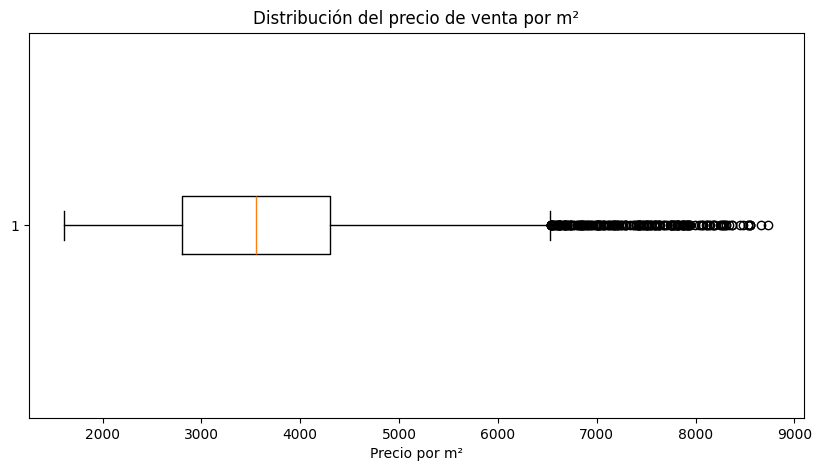

In [92]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    ventas_analisis["precio_venta_m2"].dropna(),
    vert=False
)

plt.title("Distribución del precio de venta por m²")
plt.xlabel("Precio por m²")

plt.show()

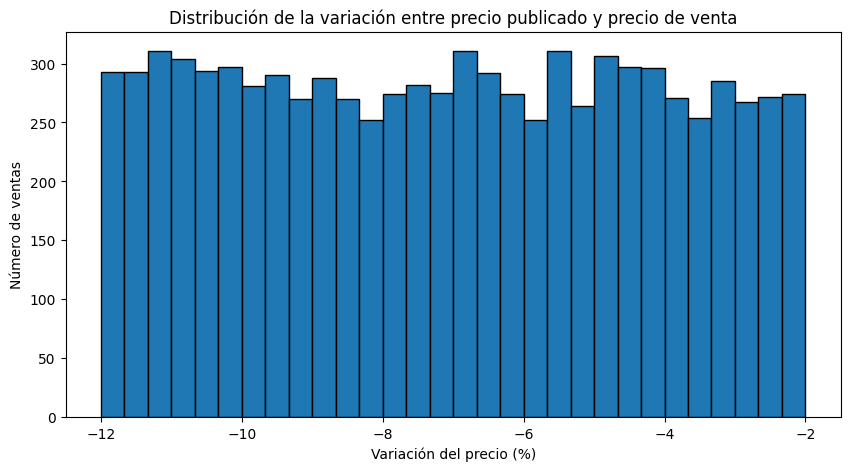

In [93]:
plt.figure(figsize=(10, 5))

plt.hist(
    ventas_analisis["variacion_precio_pct"],
    bins=30,
    edgecolor="black"
)

plt.title(
    "Distribución de la variación entre precio publicado y precio de venta"
)

plt.xlabel("Variación del precio (%)")
plt.ylabel("Número de ventas")

plt.show()

## 16. Análisis de valores extremos en precio por m²

El método IQR identificó 216 observaciones con un precio de venta por metro
cuadrado superior al límite estadístico.

Sin embargo, en bienes raíces estos valores no deben considerarse errores
automáticamente, ya que pueden estar asociados con ubicaciones, tipos de
propiedad o segmentos de mayor valor.

Por ello, se analizará su distribución por:

- Ciudad
- Barrio
- Tipo de propiedad
- Categoría de propiedad

In [94]:
outliers_m2 = ventas_analisis[
    ventas_analisis["outlier_precio_m2"]
].copy()

print("Total de outliers:", len(outliers_m2))

print(
    "Porcentaje:",
    round(
        len(outliers_m2)
        / len(ventas_analisis)
        * 100,
        2
    ),
    "%"
)

Total de outliers: 216
Porcentaje: 2.54 %


In [95]:
outliers_por_ciudad = (
    outliers_m2
    .groupby("ciudad")
    .agg(
        cantidad=("id_venta", "count"),
        precio_m2_promedio=("precio_venta_m2", "mean"),
        precio_m2_mediana=("precio_venta_m2", "median"),
        precio_m2_max=("precio_venta_m2", "max")
    )
    .sort_values(
        "cantidad",
        ascending=False
    )
)

outliers_por_ciudad

,cantidad,precio_m2_promedio,precio_m2_mediana,precio_m2_max
ciudad,,,,
Ciudad de México,201,7442.822391,7440.626943,8736.098000
Bogotá,15,6597.905953,6594.064815,6727.857143


Ahora compáralo contra todas las ventas:

In [96]:
precio_m2_ciudad = (
    ventas_analisis
    .groupby("ciudad")
    .agg(
        ventas=("id_venta", "count"),
        precio_m2_promedio=("precio_venta_m2", "mean"),
        precio_m2_mediana=("precio_venta_m2", "median"),
        precio_m2_max=("precio_venta_m2", "max")
    )
    .sort_values(
        "precio_m2_mediana",
        ascending=False
    )
)

precio_m2_ciudad

,ventas,precio_m2_promedio,precio_m2_mediana,precio_m2_max
ciudad,,,,
Ciudad de México,4123,4015.199015,3897.284024,8736.098000
Bogotá,4377,3319.141899,3267.151515,6727.857143


Esto nos permitirá distinguir:
Ciudad con muchos outliers
          +
precio/m² general alto
          ↓
probablemente comportamiento real

### 17. Porcentaje de outliers por ciudad
Contar solamente los outliers puede engañar, porque una ciudad con más ventas naturalmente puede tener más casos.

Vamos a calcular:
\[
\text{Outlier Rate} =
\frac{\text{Outliers ciudad}}
{\text{Ventas ciudad}}
\times 100
\]

In [97]:
ventas_por_ciudad = (
    ventas_analisis
    .groupby("ciudad")
    .size()
    .rename("ventas")
)

outliers_ciudad = (
    outliers_m2
    .groupby("ciudad")
    .size()
    .rename("outliers")
)

resumen_outliers_ciudad = pd.concat(
    [
        ventas_por_ciudad,
        outliers_ciudad
    ],
    axis=1
).fillna(0)

resumen_outliers_ciudad["porcentaje_outliers"] = (
    resumen_outliers_ciudad["outliers"]
    / resumen_outliers_ciudad["ventas"]
    * 100
)

resumen_outliers_ciudad.sort_values(
    "porcentaje_outliers",
    ascending=False
)

,ventas,outliers,porcentaje_outliers
ciudad,,,
Ciudad de México,4123,201,4.875091
Bogotá,4377,15,0.342700


18. Analizar por barrio
Ahora hacemos lo mismo por barrio:

In [98]:
outliers_barrio = (
    outliers_m2
    .groupby(
        [
            "ciudad",
            "barrio"
        ]
    )
    .agg(
        cantidad=("id_venta", "count"),
        precio_m2_promedio=("precio_venta_m2", "mean"),
        precio_m2_mediana=("precio_venta_m2", "median"),
        precio_m2_max=("precio_venta_m2", "max")
    )
    .sort_values(
        "cantidad",
        ascending=False
    )
)

outliers_barrio.head(15)

cantidad  precio_m2_promedio  \
ciudad           barrio                                               
Ciudad de México Del Valle                   34         7473.969933   
                 Roma Norte                  26         7404.586319   
                 Coyoacán                    23         7387.933534   
                 Polanco                     21         7308.254624   
                 Interlomas                  18         7382.760972   
                 San Ángel                   18         7245.545228   
                 Reforma                     17         7426.510002   
                 Condesa                     16         7711.759335   
                 Lomas de Chapultepec        15         7678.589549   
                 Santa Fe                    13         7526.929691   
Bogotá           Rosales                      4         6589.704176   
                 Chapinero                    3         6632.730476   
                 Chicó                        2         6535.208122   
                 Cedritos                     1         6554.765568   
                 Usaquén                      1         6727.857143   

                                       precio_m2_mediana  precio_m2_max  
ciudad           barrio                                                  
Ciudad de México Del Valle                   7586.867937    8528.164760  
                 Roma Norte                  7377.081764    8661.680597  
                 Coyoacán                    7418.386965    8286.717314  
                 Polanco                     7412.530357    8736.098000  
                 Interlomas                  7296.702573    8333.165939  
                 San Ángel                   7232.790188    8555.015873  
                 Reforma                     7438.484375    8368.926339  
                 Condesa                     7810.998048    8546.362637  
                 Lomas de Chapultepec        7924.034221    8545.240909  
                 Santa Fe                    7470.076923    8244.906977  
Bogotá           Rosales                     6575.786499    6673.618705  
                 Chapinero                   6620.631148    6669.008197  
                 Chicó                       6535.208122    6536.212230  
                 Cedritos                    6554.765568    6554.765568  
                 Usaquén                     6727.857143    6727.857143

Los valores extremos no están distribuidos aleatoriamente; se concentran en ciertos barrios.

### 19. Tipo de propiedad

In [99]:
outliers_tipo = (
    outliers_m2
    .groupby("tipo_propiedad")
    .agg(
        cantidad=("id_venta", "count"),
        precio_m2_promedio=("precio_venta_m2", "mean"),
        precio_m2_mediana=("precio_venta_m2", "median")
    )
    .sort_values(
        "cantidad",
        ascending=False
    )
)

outliers_tipo

,cantidad,precio_m2_promedio,precio_m2_mediana
tipo_propiedad,,,
Comercial,216,7384.147638,7405.439597


Y nuevamente calculemos tasa, no solo cantidad:

In [100]:
ventas_tipo = (
    ventas_analisis
    .groupby("tipo_propiedad")
    .size()
    .rename("ventas")
)

outliers_tipo_count = (
    outliers_m2
    .groupby("tipo_propiedad")
    .size()
    .rename("outliers")
)

resumen_tipo = pd.concat(
    [
        ventas_tipo,
        outliers_tipo_count
    ],
    axis=1
).fillna(0)

resumen_tipo["porcentaje_outliers"] = (
    resumen_tipo["outliers"]
    / resumen_tipo["ventas"]
    * 100
)

resumen_tipo.sort_values(
    "porcentaje_outliers",
    ascending=False
)

,ventas,outliers,porcentaje_outliers
tipo_propiedad,,,
Comercial,1071,216.0,20.168067
Casa,2324,0.0,0.000000
Departamento,5105,0.0,0.000000


### 20. Visualización

Precio por m² por ciudad

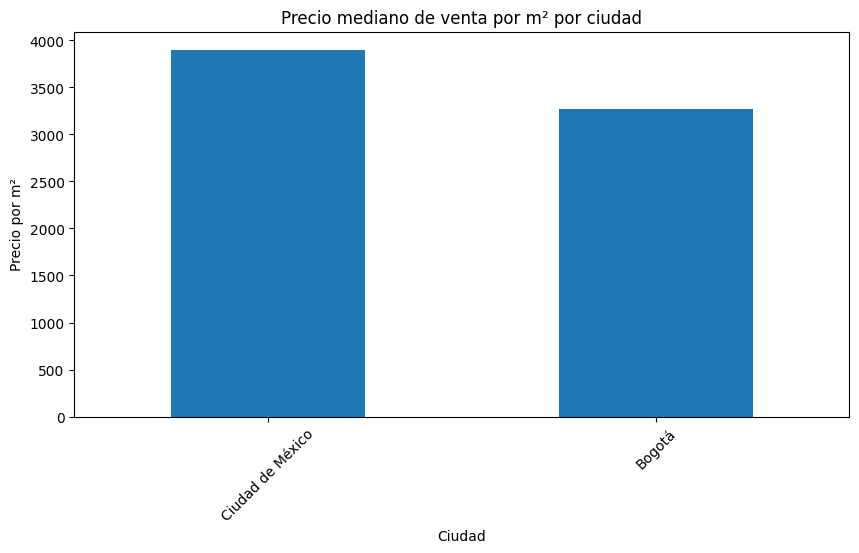

In [101]:
precio_ciudad_plot = (
    ventas_analisis
    .groupby("ciudad")["precio_venta_m2"]
    .median()
    .sort_values(
        ascending=False
    )
)

plt.figure(figsize=(10, 5))

precio_ciudad_plot.plot(
    kind="bar"
)

plt.title(
    "Precio mediano de venta por m² por ciudad"
)

plt.xlabel("Ciudad")
plt.ylabel("Precio por m²")

plt.xticks(rotation=45)

plt.show()

Uso la mediana deliberadamente porque es menos sensible a valores extremos.
### Outliers por ciudad

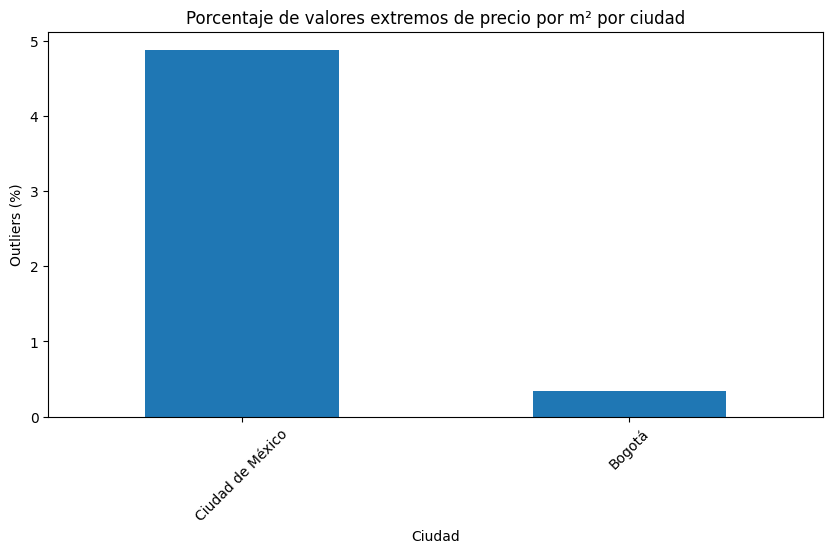

In [102]:
plot_outliers = (
    resumen_outliers_ciudad[
        "porcentaje_outliers"
    ]
    .sort_values(
        ascending=False
    )
)

plt.figure(figsize=(10, 5))

plot_outliers.plot(
    kind="bar"
)

plt.title(
    "Porcentaje de valores extremos de precio por m² por ciudad"
)

plt.xlabel("Ciudad")
plt.ylabel("Outliers (%)")

plt.xticks(rotation=45)

plt.show()

### 21. Una comprobación adicional: propiedades pequeñas
Hay una causa matemática frecuente de precios altos por m²:
\[
P_{m^2} =
\frac{Precio}{Tamaño}
\]
Si el denominador tamano_m2 es pequeño, el resultado puede aumentar mucho.

Vamos a comprobarlo:

In [103]:
outliers_m2[
    [
        "tamano_m2",
        "precio_venta",
        "precio_venta_m2"
    ]
].describe()

,tamano_m2,precio_venta,precio_venta_m2
count,216.000000,2.160000e+02,216.000000
mean,335.796296,2.485851e+06,7384.147638
std,159.777418,1.211996e+06,575.078210
min,82.000000,5.512910e+05,6533.417417
25%,198.000000,1.405039e+06,6866.090333
50%,338.000000,2.526071e+06,7405.439597
75%,474.000000,3.418251e+06,7820.651875
max,598.000000,4.944525e+06,8736.098000


In [104]:
ventas_analisis[
    [
        "tamano_m2",
        "precio_venta",
        "precio_venta_m2"
    ]
].describe()

,tamano_m2,precio_venta,precio_venta_m2
count,8500.000000,8.500000e+03,8500.000000
mean,179.131529,7.073532e+05,3656.770545
std,113.537765,6.458332e+05,1166.678628
min,45.000000,7.683700e+04,1608.049080
25%,98.000000,3.070042e+05,2807.298247
50%,145.000000,4.891235e+05,3554.150804
75%,231.000000,8.669085e+05,4297.702091
max,599.000000,4.944525e+06,8736.098000


In [105]:
print(
    "Mediana tamaño general:",
    ventas_analisis["tamano_m2"].median()
)

print(
    "Mediana tamaño outliers:",
    outliers_m2["tamano_m2"].median()
)

Mediana tamaño general: 145.0
Mediana tamaño outliers: 338.0


### Decisión sobre valores extremos

El método IQR identificó valores estadísticamente extremos en algunas
variables. Sin embargo, no se eliminaron automáticamente.

En particular:

- La diferencia absoluta entre precio publicado y precio vendido presentó
  valores extremos, pero la variación porcentual no mostró outliers.
- Los precios elevados por metro cuadrado pueden estar explicados por
  ubicación, tipo de propiedad y tamaño.
- Las diferencias en comisiones fueron pequeñas en términos relativos y
  compatibles con efectos de redondeo.

Por lo tanto, los valores extremos se conservaron mientras fueran
consistentes con las reglas de negocio y no existiera evidencia de errores
de captura.

Esta decisión evita eliminar observaciones legítimas del mercado inmobiliario.

### 23. Cerrar el ETL con un reporte de calidad
Ahora podemos crear una pequeña tabla resumen:

In [106]:
reporte_calidad = pd.DataFrame({
    "Dataset": [
        "Clientes",
        "Propiedades",
        "Ventas"
    ],

    "Registros": [
        len(clientes),
        len(propiedades),
        len(ventas_normalizadas)
    ],

    "Duplicados": [
        clientes.duplicated().sum(),
        propiedades.duplicated().sum(),
        ventas_normalizadas.duplicated().sum()
    ],

    "Valores_nulos": [
        clientes.isna().sum().sum(),
        propiedades.isna().sum().sum(),
        ventas_normalizadas.isna().sum().sum()
    ]
})

reporte_calidad

,Dataset,Registros,Duplicados,Valores_nulos
0,Clientes,3500,0,0
1,Propiedades,8000,0,0
2,Ventas,8500,0,0


### 24. Exportar los datos limpios

In [ ]:
#clientes.to_csv("../data/processed/dim_clientes_clean.csv", index=False )

#propiedades.to_csv("../data/processed/dim_propiedades_clean.csv",index=False)

#ventas_normalizadas.to_csv("../data/processed/hechos_ventas_propiedades_clean.csv",index=False)

## 25. KPIs principales del negocio

Una vez validados y normalizados los datos, se calculan los indicadores
principales de desempeño comercial.

### Ingreso total

$$
Ingreso\ Total = \sum_{i=1}^{n} PrecioVenta_i
$$

### Cantidad de ventas

$$
Cantidad\ de\ Ventas = n
$$

### Ticket promedio

$$
Ticket\ Promedio =
\frac{\sum PrecioVenta}{Cantidad\ de\ Ventas}
$$

### Comisión total

$$
Comisión\ Total =
\sum_{i=1}^{n} MontoComision_i
$$

In [107]:
ingreso_total = ventas["precio_venta"].sum()

cantidad_ventas = ventas["id_venta"].nunique()

ticket_promedio = ventas["precio_venta"].mean()

comision_total = ventas["monto_comision"].sum()

print(f"Ingreso total: ${ingreso_total:,.2f}")
print(f"Cantidad de ventas: {cantidad_ventas:,}")
print(f"Ticket promedio: ${ticket_promedio:,.2f}")
print(f"Comisión total: ${comision_total:,.2f}")

Ingreso total: $6,012,502,170.00
Cantidad de ventas: 8,500
Ticket promedio: $707,353.20
Comisión total: $200,627,166.00


### 26. Evolución mensual de ingresos
Esta será una de las visualizaciones principales.

Primero asegúrate de que la fecha sea tipo datetime:

In [108]:
ventas["fecha_venta"] = pd.to_datetime(
    ventas["fecha_venta"],
    errors="coerce"
)

Ahora crea una columna mensual:

In [109]:
ventas["mes"] = (
    ventas["fecha_venta"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

Agrupamos:

In [110]:
ventas_mensuales = (
    ventas
    .groupby("mes")
    .agg(
        ingreso=("precio_venta", "sum"),
        ventas=("id_venta", "nunique"),
        ticket_promedio=("precio_venta", "mean"),
        comision=("monto_comision", "sum")
    )
    .reset_index()
)

ventas_mensuales.head()

,mes,ingreso,ventas,ticket_promedio,comision
0,2023-01-01,162741008,224,726522.357143,5383002
1,2023-02-01,180172127,247,729441.809717,5716076
2,2023-03-01,346782891,434,799038.919355,11715435
3,2023-04-01,330950703,473,699684.361522,10747819
4,2023-05-01,186047939,290,641544.617241,6267890


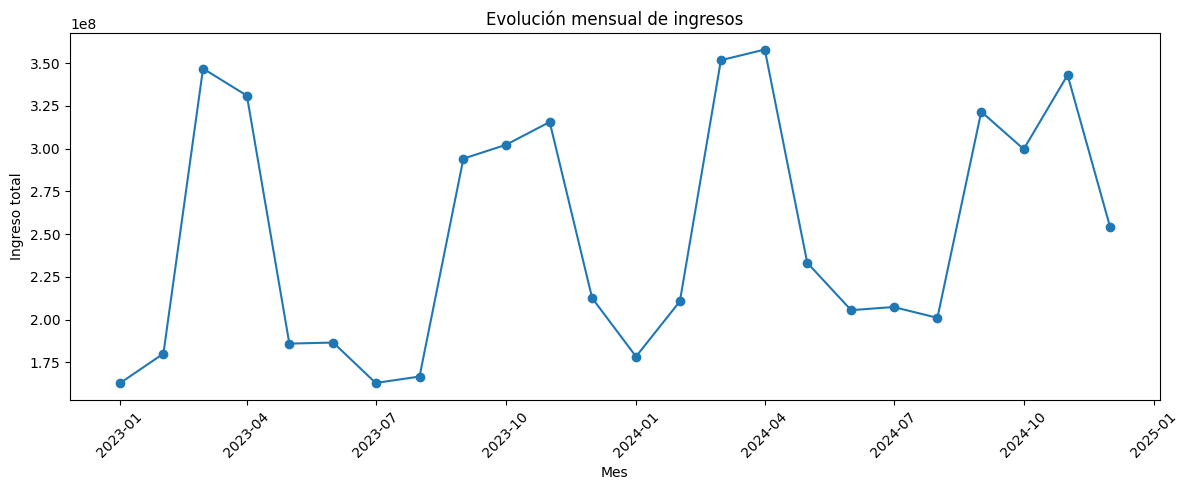

In [111]:
plt.figure(figsize=(12, 5))

plt.plot(
    ventas_mensuales["mes"],
    ventas_mensuales["ingreso"],
    marker="o"
)

plt.title("Evolución mensual de ingresos")
plt.xlabel("Mes")
plt.ylabel("Ingreso total")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 27. Crecimiento mensual
Ahora agregamos una métrica que mejora bastante el análisis:
\[
Growth_t =
\frac{Ingreso_t-Ingreso_{t-1}}
{Ingreso_{t-1}}
\times100
\]

In [112]:
ventas_mensuales["crecimiento_ingreso_pct"] = (
    ventas_mensuales["ingreso"]
    .pct_change()
    * 100
)

In [113]:
ventas_mensuales[
    [
        "mes",
        "ingreso",
        "crecimiento_ingreso_pct"
    ]
]

,mes,ingreso,crecimiento_ingreso_pct
0,2023-01-01,162741008,NaN
1,2023-02-01,180172127,10.710957
2,2023-03-01,346782891,92.473107
3,2023-04-01,330950703,-4.565447
4,2023-05-01,186047939,-43.783791
5,2023-06-01,186643186,0.319943
6,2023-07-01,163044045,-12.643987
7,2023-08-01,166773927,2.287653
8,2023-09-01,294152624,76.378064
9,2023-10-01,302194159,2.733797


In [114]:
mejor_mes = ventas_mensuales.loc[
    ventas_mensuales["ingreso"].idxmax()
]

peor_mes = ventas_mensuales.loc[
    ventas_mensuales["ingreso"].idxmin()
]

print(
    "Mes con mayor ingreso:",
    mejor_mes["mes"],
    f"${mejor_mes['ingreso']:,.2f}"
)

print(
    "Mes con menor ingreso:",
    peor_mes["mes"],
    f"${peor_mes['ingreso']:,.2f}"
)

Mes con mayor ingreso: 2024-04-01 00:00:00 $357,905,809.00
Mes con menor ingreso: 2023-01-01 00:00:00 $162,741,008.00


### 28. Desempeño por ciudad
Ahora queremos responder:
¿Qué mercados generan más ingresos y ventas?

In [115]:
desempeno_ciudad = (
    ventas
    .groupby("ciudad")
    .agg(
        ingreso_total=("precio_venta", "sum"),
        ventas=("id_venta", "nunique"),
        ticket_promedio=("precio_venta", "mean"),
        comision_total=("monto_comision", "sum")
    )
    .sort_values(
        "ingreso_total",
        ascending=False
    )
)

desempeno_ciudad

,ingreso_total,ventas,ticket_promedio,comision_total
ciudad,,,,
Ciudad de México,3242231285,4123,786376.736600,108204490
Bogotá,2770270885,4377,632915.440941,92422676


Y una métrica adicional:
\[
Participación =
\frac{IngresoCiudad}{IngresoTotal}
\times100
\]

In [116]:
desempeno_ciudad["participacion_ingresos_pct"] = (
    desempeno_ciudad["ingreso_total"]
    / ingreso_total
    * 100
)

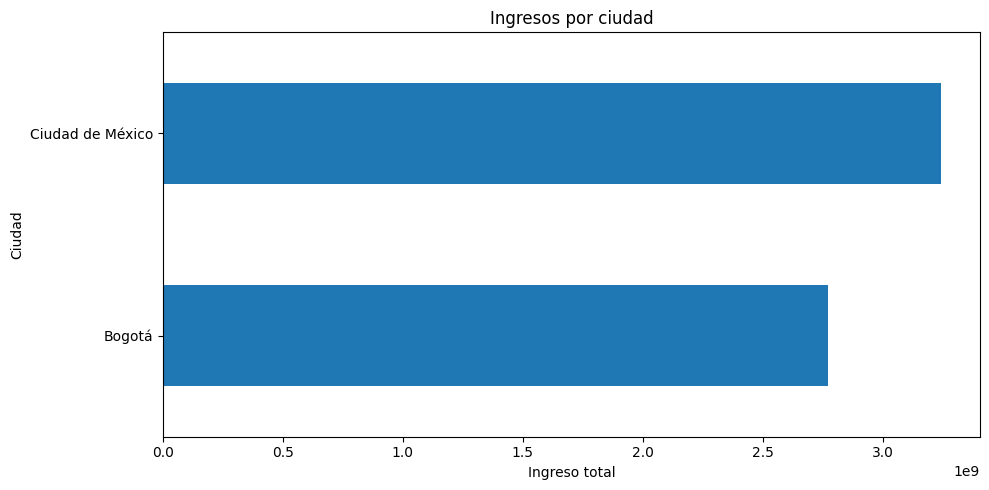

In [117]:
plt.figure(figsize=(10, 5))

desempeno_ciudad[
    "ingreso_total"
].sort_values().plot(
    kind="barh"
)

plt.title("Ingresos por ciudad")
plt.xlabel("Ingreso total")
plt.ylabel("Ciudad")

plt.tight_layout()
plt.show()

### 29. Desempeño por tipo de propiedad

In [118]:
desempeno_tipo = (
    ventas
    .groupby("tipo_propiedad")
    .agg(
        ingreso_total=("precio_venta", "sum"),
        ventas=("id_venta", "nunique"),
        ticket_promedio=("precio_venta", "mean")
    )
    .sort_values(
        "ingreso_total",
        ascending=False
    )
)

desempeno_tipo

,ingreso_total,ventas,ticket_promedio
tipo_propiedad,,,
Casa,2240535304,2324,9.640858e+05
Comercial,1924691634,1071,1.797098e+06
Departamento,1847275232,5105,3.618561e+05


Como queremos mostrar que trabajamos con el modelo normalizado, para el análisis final es mejor usar:

In [119]:
ventas_modelo = ventas_normalizadas.merge(
    propiedades[
        [
            "id_propiedad",
            "tipo_propiedad",
            "categoria_propiedad",
            "ciudad",
            "barrio",
            "tamano_m2",
            "precio_publicado"
        ]
    ],
    on="id_propiedad",
    how="left"
)

Y a partir de aquí utilizar ventas_modelo.

### 30. Canales de venta
Esta parte será importante porque aparece claramente en tu dashboard de Power BI.

In [120]:
canales = (
    ventas_modelo
    .groupby("canal_venta")
    .agg(
        ventas=("id_venta", "nunique"),
        ingreso_total=("precio_venta", "sum"),
        ticket_promedio=("precio_venta", "mean"),
        comision_total=("monto_comision", "sum")
    )
    .sort_values(
        "ingreso_total",
        ascending=False
    )
)

canales

,ventas,ingreso_total,ticket_promedio,comision_total
canal_venta,,,,
Corredor,6181,4379990279,708621.627407,176173560
Directo,2319,1632511891,703972.354894,24453606


Agrega participación:

In [121]:
canales["participacion_ventas_pct"] = (
    canales["ventas"]
    / cantidad_ventas
    * 100
)

canales["participacion_ingresos_pct"] = (
    canales["ingreso_total"]
    / ingreso_total
    * 100
)

Aquí podremos responder algo mucho más útil que “qué canal vende más”:

¿El canal con más operaciones también es el que genera más ingresos?

### 31. Segmentos de clientes
Ahora sí utilizamos dim_clientes.

In [123]:
ventas_completas = ventas_modelo.merge(
    clientes[
        [
            "id_cliente",
            "segmento_comprador",
            "pais"
        ]
    ],
    on="id_cliente",
    how="left"
)

In [124]:
segmentos = (
    ventas_completas
    .groupby("segmento_comprador")
    .agg(
        clientes=("id_cliente", "nunique"),
        ventas=("id_venta", "nunique"),
        ingreso_total=("precio_venta", "sum"),
        ticket_promedio=("precio_venta", "mean")
    )
    .sort_values(
        "ingreso_total",
        ascending=False
    )
)

segmentos

,clientes,ventas,ingreso_total,ticket_promedio
segmento_comprador,,,,
Primera vez,1770,5302,3783579998,713613.730290
Inversionista,914,2093,1471444845,703031.459627
Alto patrimonio,455,1105,757477327,685499.843439


Una métrica especialmente útil:
\[
VentasPorCliente =
\frac{Ventas}{ClientesUnicos}
\]

In [125]:
segmentos["ventas_por_cliente"] = (
    segmentos["ventas"]
    / segmentos["clientes"]
)

Esto empieza a acercarnos a la parte de recurrencia y cohortes.

### 32. Qué quiero validar ahora
Antes de seguir con cohortes, ejecuta principalmente estas tres salidas:

In [126]:
print(f"Ingreso total: ${ingreso_total:,.2f}")
print(f"Cantidad de ventas: {cantidad_ventas:,}")
print(f"Ticket promedio: ${ticket_promedio:,.2f}")
print(f"Comisión total: ${comision_total:,.2f}")

Ingreso total: $6,012,502,170.00
Cantidad de ventas: 8,500
Ticket promedio: $707,353.20
Comisión total: $200,627,166.00


In [127]:
ventas_mensuales

,mes,ingreso,ventas,ticket_promedio,comision,crecimiento_ingreso_pct
0,2023-01-01,162741008,224,726522.357143,5383002,NaN
1,2023-02-01,180172127,247,729441.809717,5716076,10.710957
2,2023-03-01,346782891,434,799038.919355,11715435,92.473107
3,2023-04-01,330950703,473,699684.361522,10747819,-4.565447
4,2023-05-01,186047939,290,641544.617241,6267890,-43.783791
5,2023-06-01,186643186,270,691271.059259,6001942,0.319943
6,2023-07-01,163044045,241,676531.307054,5504314,-12.643987
7,2023-08-01,166773927,268,622290.772388,5656038,2.287653
8,2023-09-01,294152624,405,726302.775309,10044108,76.378064
9,2023-10-01,302194159,433,697907.988453,10035821,2.733797


In [128]:
canales

,ventas,ingreso_total,ticket_promedio,comision_total,participacion_ventas_pct,participacion_ingresos_pct
canal_venta,,,,,,
Corredor,6181,4379990279,708621.627407,176173560,72.717647,72.848045
Directo,2319,1632511891,703972.354894,24453606,27.282353,27.151955


## 33. Análisis de clientes nuevos y recurrentes

Para estudiar adquisición y recurrencia se identifica la primera compra
registrada de cada cliente.

$$
FechaPrimeraCompra_i =
\min(FechaVenta_i)
$$

Un cliente será considerado:

- **Nuevo:** si la venta corresponde al mes de su primera compra.
- **Recurrente:** si realizó compras posteriores a su primera compra.

In [129]:
primera_compra = (
    ventas_completas
    .groupby("id_cliente")["fecha_venta"]
    .min()
    .rename("fecha_primera_compra")
)

ventas_clientes = ventas_completas.merge(
    primera_compra,
    on="id_cliente",
    how="left"
)

ventas_clientes[
    [
        "id_cliente",
        "fecha_venta",
        "fecha_primera_compra"
    ]
].head()

,id_cliente,fecha_venta,fecha_primera_compra
0,CUST02497,2024-01-05,2024-01-05
1,CUST02903,2024-06-16,2024-03-15
2,CUST00831,2024-10-13,2024-10-13
3,CUST01686,2023-02-08,2023-01-27
4,CUST00639,2024-11-29,2024-07-15


In [132]:
ventas_completas["fecha_venta"] = pd.to_datetime(
    ventas_completas["fecha_venta"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [133]:
ventas_completas["fecha_venta"].dtype

dtype('<M8[ns]')

In [134]:
ventas_completas["fecha_venta"].isna().sum()

np.int64(0)

In [135]:
primera_compra = (
    ventas_completas
    .groupby("id_cliente")["fecha_venta"]
    .min()
    .rename("fecha_primera_compra")
)

In [136]:
ventas_clientes = ventas_completas.merge(
    primera_compra,
    on="id_cliente",
    how="left"
)

In [137]:
ventas_clientes[
    [
        "fecha_venta",
        "fecha_primera_compra"
    ]
].dtypes

fecha_venta             datetime64[ns]
fecha_primera_compra    datetime64[ns]
dtype: object

In [138]:
ventas_clientes["mes_venta"] = (
    ventas_clientes["fecha_venta"]
    .dt.to_period("M")
)

ventas_clientes["mes_adquisicion"] = (
    ventas_clientes["fecha_primera_compra"]
    .dt.to_period("M")
)

In [139]:
ventas_clientes[
    [
        "id_cliente",
        "fecha_venta",
        "fecha_primera_compra",
        "mes_venta",
        "mes_adquisicion"
    ]
].head(10)

,id_cliente,fecha_venta,fecha_primera_compra,mes_venta,mes_adquisicion
0,CUST02497,2024-01-05,2024-01-05,2024-01,2024-01
1,CUST02903,2024-06-16,2024-03-15,2024-06,2024-03
2,CUST00831,2024-10-13,2024-10-13,2024-10,2024-10
3,CUST01686,2023-02-08,2023-01-27,2023-02,2023-01
4,CUST00639,2024-11-29,2024-07-15,2024-11,2024-07
5,CUST00900,2023-02-11,2023-02-11,2023-02,2023-02
6,CUST02807,2023-07-13,2023-07-13,2023-07,2023-07
7,CUST03356,2023-12-31,2023-02-15,2023-12,2023-02
8,CUST00620,2023-03-01,2023-03-01,2023-03,2023-03
9,CUST01132,2023-01-14,2023-01-14,2023-01,2023-01


In [140]:
ventas_clientes["mes_venta"] = (
    ventas_clientes["fecha_venta"]
    .dt.to_period("M")
)

ventas_clientes["mes_adquisicion"] = (
    ventas_clientes["fecha_primera_compra"]
    .dt.to_period("M")
)

In [141]:
ventas_clientes["tipo_cliente_periodo"] = np.where(
    ventas_clientes["mes_venta"]
    == ventas_clientes["mes_adquisicion"],
    "Nuevo",
    "Recurrente"
)

In [142]:
ventas_clientes[
    [
        "id_cliente",
        "fecha_venta",
        "mes_adquisicion",
        "tipo_cliente_periodo"
    ]
].head(20)

,id_cliente,fecha_venta,mes_adquisicion,tipo_cliente_periodo
0,CUST02497,2024-01-05,2024-01,Nuevo
1,CUST02903,2024-06-16,2024-03,Recurrente
2,CUST00831,2024-10-13,2024-10,Nuevo
3,CUST01686,2023-02-08,2023-01,Recurrente
4,CUST00639,2024-11-29,2024-07,Recurrente
5,CUST00900,2023-02-11,2023-02,Nuevo
6,CUST02807,2023-07-13,2023-07,Nuevo
7,CUST03356,2023-12-31,2023-02,Recurrente
8,CUST00620,2023-03-01,2023-03,Nuevo
9,CUST01132,2023-01-14,2023-01,Nuevo


34. Clientes nuevos por mes
Aquí conviene contar clientes únicos, no ventas.

In [143]:
clientes_nuevos_mes = (
    ventas_clientes[
        ventas_clientes["tipo_cliente_periodo"]
        == "Nuevo"
    ]
    .groupby("mes_venta")["id_cliente"]
    .nunique()
    .rename("clientes_nuevos")
)

clientes_nuevos_mes

mes_venta
2023-01    212
2023-02    227
2023-03    353
2023-04    346
2023-05    184
2023-06    155
2023-07    128
2023-08    145
2023-09    180
2023-10    176
2023-11    155
2023-12    105
2024-01     72
2024-02     78
2024-03    123
2024-04    107
2024-05     72
2024-06     52
2024-07     43
2024-08     40
2024-09     57
2024-10     49
2024-11     54
2024-12     26
Freq: M, Name: clientes_nuevos, dtype: int64

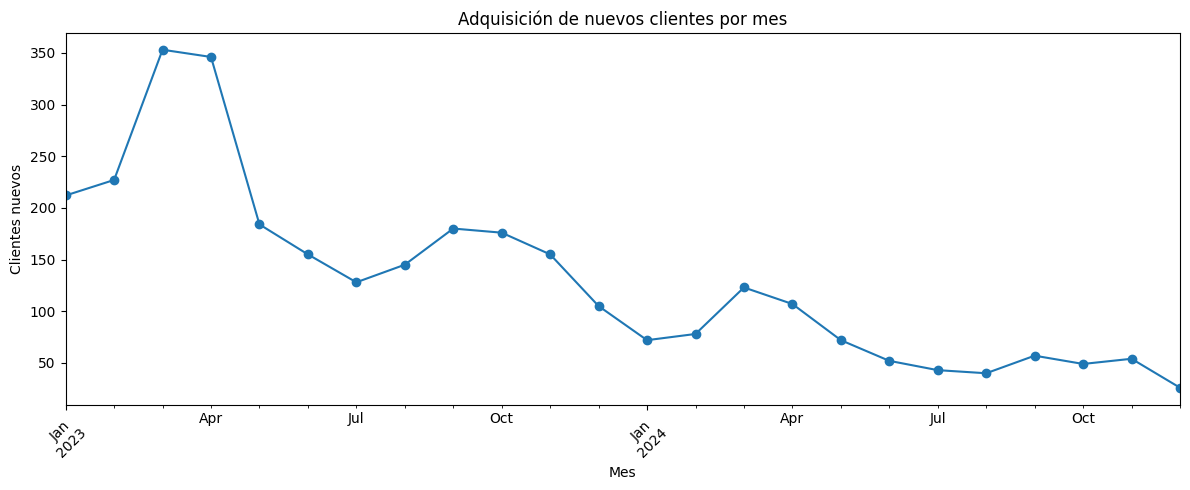

In [144]:
plt.figure(figsize=(12, 5))

clientes_nuevos_mes.plot(
    marker="o"
)

plt.title("Adquisición de nuevos clientes por mes")
plt.xlabel("Mes")
plt.ylabel("Clientes nuevos")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Esto responde:

¿En qué meses el negocio adquirió más compradores nuevos?

### 35. Clientes recurrentes por mes

In [145]:
clientes_recurrentes_mes = (
    ventas_clientes[
        ventas_clientes["tipo_cliente_periodo"]
        == "Recurrente"
    ]
    .groupby("mes_venta")["id_cliente"]
    .nunique()
    .rename("clientes_recurrentes")
)

clientes_recurrentes_mes

mes_venta
2023-02     11
2023-03     58
2023-04    105
2023-05     92
2023-06     96
2023-07    104
2023-08    108
2023-09    199
2023-10    232
2023-11    278
2023-12    184
2024-01    183
2024-02    188
2024-03    335
2024-04    347
2024-05    250
2024-06    243
2024-07    230
2024-08    222
2024-09    354
2024-10    373
2024-11    403
2024-12    314
Freq: M, Name: clientes_recurrentes, dtype: int64

In [146]:
clientes_mes = pd.concat(
    [
        clientes_nuevos_mes,
        clientes_recurrentes_mes
    ],
    axis=1
).fillna(0)

clientes_mes

,clientes_nuevos,clientes_recurrentes
mes_venta,,
2023-01,212,0.0
2023-02,227,11.0
2023-03,353,58.0
2023-04,346,105.0
2023-05,184,92.0
2023-06,155,96.0
2023-07,128,104.0
2023-08,145,108.0
2023-09,180,199.0


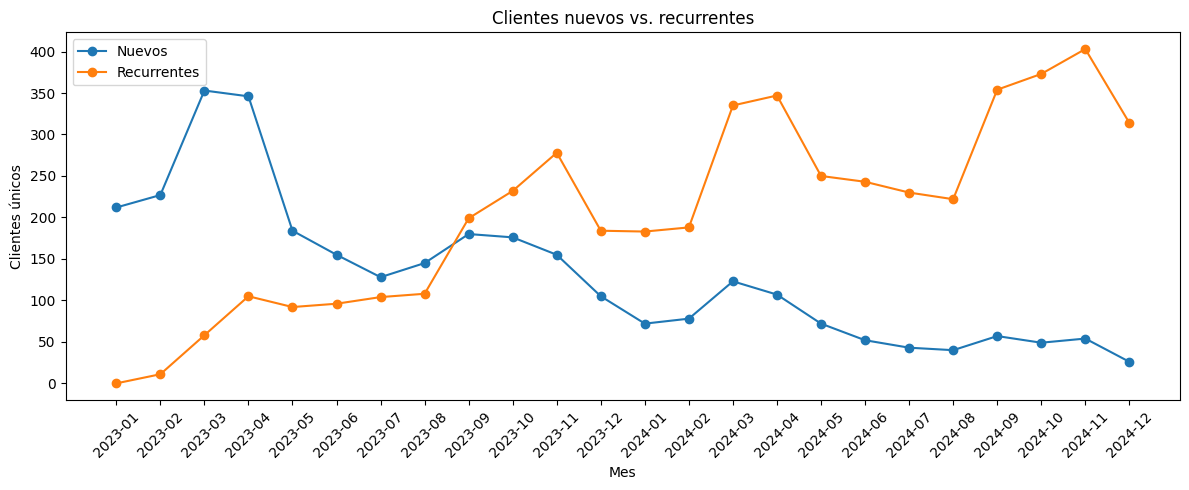

In [147]:
plt.figure(figsize=(12, 5))

plt.plot(
    clientes_mes.index.astype(str),
    clientes_mes["clientes_nuevos"],
    marker="o",
    label="Nuevos"
)

plt.plot(
    clientes_mes.index.astype(str),
    clientes_mes["clientes_recurrentes"],
    marker="o",
    label="Recurrentes"
)

plt.title("Clientes nuevos vs. recurrentes")
plt.xlabel("Mes")
plt.ylabel("Clientes únicos")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

36. Tasa de recompra
Ahora podemos construir una métrica muy útil.

Definimos cliente recurrente como aquel que realizó más de una compra:
\[
TasaRecompra =
\frac{Clientes\ con\ más\ de\ una\ compra}
{Clientes\ totales}
\times100
\]
Primero contamos compras por cliente:

In [148]:
compras_por_cliente = (
    ventas_clientes
    .groupby("id_cliente")
    .agg(
        cantidad_compras=("id_venta", "nunique"),
        gasto_total=("precio_venta", "sum"),
        ticket_promedio=("precio_venta", "mean")
    )
)

compras_por_cliente.head()

,cantidad_compras,gasto_total,ticket_promedio
id_cliente,,,
CUST00001,1,708699,7.086990e+05
CUST00003,6,2632490,4.387483e+05
CUST00004,2,2061099,1.030550e+06
CUST00005,4,3104531,7.761328e+05
CUST00006,3,2844484,9.481613e+05


In [149]:
clientes_totales = (
    compras_por_cliente.shape[0]
)

clientes_recurrentes = (
    compras_por_cliente[
        "cantidad_compras"
    ] > 1
).sum()

tasa_recompra = (
    clientes_recurrentes
    / clientes_totales
    * 100
)

print(
    f"Clientes totales: {clientes_totales:,}"
)

print(
    f"Clientes recurrentes: {clientes_recurrentes:,}"
)

print(
    f"Tasa de recompra: {tasa_recompra:.2f}%"
)

Clientes totales: 3,139
Clientes recurrentes: 2,421
Tasa de recompra: 77.13%


Esta métrica debería son importantes para el dashboard técnico.

37. Frecuencia de compra
También podemos responder:
¿Cuántas propiedades compra en promedio cada cliente?

\[
FrecuenciaPromedio =
\frac{VentasTotales}
{ClientesÚnicos}
\]

In [151]:
frecuencia_promedio = (
    cantidad_ventas
    / clientes_totales
)

print(
    f"Compras promedio por cliente en todo el registro: "
    f"{frecuencia_promedio:.2f}"
)

Compras promedio por cliente en todo el registro: 2.71


Y observamos la distribucion

In [152]:
compras_por_cliente[
    "cantidad_compras"
].describe()

count    3139.000000
mean        2.707869
std         1.490689
min         1.000000
25%         2.000000
50%         2.000000
75%         4.000000
max        10.000000
Name: cantidad_compras, dtype: float64

In [153]:
compras_por_cliente[
    "cantidad_compras"
].value_counts().sort_index()

cantidad_compras
1     718
2     913
3     704
4     428
5     216
6      97
7      42
8      16
9       2
10      3
Name: count, dtype: int64

38. Construcción de cohortes
Ahora sí viene la parte potente.

Una cohorte será el mes en el que cada cliente hizo su primera compra.

Tenemos:
Cliente A
Primera compra → Ene 2024
↓
Cohorte Ene 2024

Luego queremos saber si ese cliente también compró:
mes 0 → adquisición
mes 1 → siguiente mes
mes 2
mes 3
...

Primero convertimos los períodos a timestamps para calcular diferencias:

In [154]:
ventas_clientes["cohorte"] = (
    ventas_clientes["fecha_primera_compra"]
    .dt.to_period("M")
)

Creamos una función para calcular la diferencia en meses:

In [155]:
def diferencia_meses(fecha, primera_fecha):
    return (
        (fecha.dt.year - primera_fecha.dt.year) * 12
        +
        (fecha.dt.month - primera_fecha.dt.month)
    )

In [156]:
ventas_clientes["indice_cohorte"] = (
    diferencia_meses(
        ventas_clientes["fecha_venta"],
        ventas_clientes["fecha_primera_compra"]
    )
)

### 39. Matriz de cohortes
Ahora contamos clientes únicos:

In [157]:
cohortes = (
    ventas_clientes
    .groupby(
        [
            "cohorte",
            "indice_cohorte"
        ]
    )["id_cliente"]
    .nunique()
    .reset_index()
)

In [158]:
matriz_cohortes = cohortes.pivot(
    index="cohorte",
    columns="indice_cohorte",
    values="id_cliente"
)

matriz_cohortes

indice_cohorte,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohorte,,,,,,,,,,,,,,,,,,,,,
2023-01,212.0,11.0,32.0,29.0,20.0,14.0,16.0,14.0,22.0,31.0,...,25.0,27.0,19.0,20.0,18.0,10.0,20.0,26.0,23.0,23.0
2023-02,227.0,26.0,29.0,18.0,14.0,22.0,14.0,30.0,25.0,35.0,...,36.0,19.0,27.0,22.0,22.0,32.0,34.0,24.0,18.0,NaN
2023-03,353.0,47.0,34.0,24.0,23.0,28.0,42.0,41.0,57.0,27.0,...,33.0,27.0,29.0,28.0,35.0,50.0,66.0,31.0,NaN,NaN
2023-04,346.0,20.0,28.0,21.0,24.0,37.0,44.0,42.0,41.0,24.0,...,26.0,26.0,29.0,42.0,49.0,42.0,33.0,NaN,NaN,NaN
2023-05,184.0,16.0,10.0,15.0,23.0,29.0,25.0,15.0,14.0,8.0,...,14.0,8.0,23.0,23.0,22.0,25.0,NaN,NaN,NaN,NaN
2023-06,155.0,12.0,7.0,19.0,20.0,16.0,11.0,12.0,10.0,29.0,...,12.0,20.0,13.0,24.0,21.0,NaN,NaN,NaN,NaN,NaN
2023-07,128.0,6.0,14.0,11.0,19.0,8.0,11.0,11.0,15.0,13.0,...,14.0,17.0,21.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,145.0,12.0,15.0,15.0,11.0,13.0,15.0,18.0,13.0,9.0,...,19.0,21.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,180.0,16.0,31.0,16.0,17.0,16.0,24.0,20.0,12.0,21.0,...,25.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 40. Retención por cohorte

La retención mide qué proporción de los clientes adquiridos durante un
periodo vuelve a realizar una compra posteriormente.

$$
Retención_{c,t} =
\frac{ClientesActivos_{c,t}}
{ClientesIniciales_c}
\times 100
$$

Donde:

- $c$ representa la cohorte de adquisición.
- $t$ representa los meses transcurridos desde la primera compra.

In [159]:
tamano_cohorte = (
    matriz_cohortes[0]
)

retencion_cohortes = (
    matriz_cohortes
    .divide(
        tamano_cohorte,
        axis=0
    )
    * 100
)

retencion_cohortes.round(2)

indice_cohorte,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohorte,,,,,,,,,,,,,,,,,,,,,
2023-01,100.0,5.19,15.09,13.68,9.43,6.60,7.55,6.60,10.38,14.62,...,11.79,12.74,8.96,9.43,8.49,4.72,9.43,12.26,10.85,10.85
2023-02,100.0,11.45,12.78,7.93,6.17,9.69,6.17,13.22,11.01,15.42,...,15.86,8.37,11.89,9.69,9.69,14.10,14.98,10.57,7.93,NaN
2023-03,100.0,13.31,9.63,6.80,6.52,7.93,11.90,11.61,16.15,7.65,...,9.35,7.65,8.22,7.93,9.92,14.16,18.70,8.78,NaN,NaN
2023-04,100.0,5.78,8.09,6.07,6.94,10.69,12.72,12.14,11.85,6.94,...,7.51,7.51,8.38,12.14,14.16,12.14,9.54,NaN,NaN,NaN
2023-05,100.0,8.70,5.43,8.15,12.50,15.76,13.59,8.15,7.61,4.35,...,7.61,4.35,12.50,12.50,11.96,13.59,NaN,NaN,NaN,NaN
2023-06,100.0,7.74,4.52,12.26,12.90,10.32,7.10,7.74,6.45,18.71,...,7.74,12.90,8.39,15.48,13.55,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,4.69,10.94,8.59,14.84,6.25,8.59,8.59,11.72,10.16,...,10.94,13.28,16.41,13.28,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,8.28,10.34,10.34,7.59,8.97,10.34,12.41,8.97,6.21,...,13.10,14.48,10.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,8.89,17.22,8.89,9.44,8.89,13.33,11.11,6.67,11.67,...,13.89,11.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 41. Heatmap de cohortes
Ya tienes matplotlib; para esta gráfica podemos hacerlo sin instalar nada más:

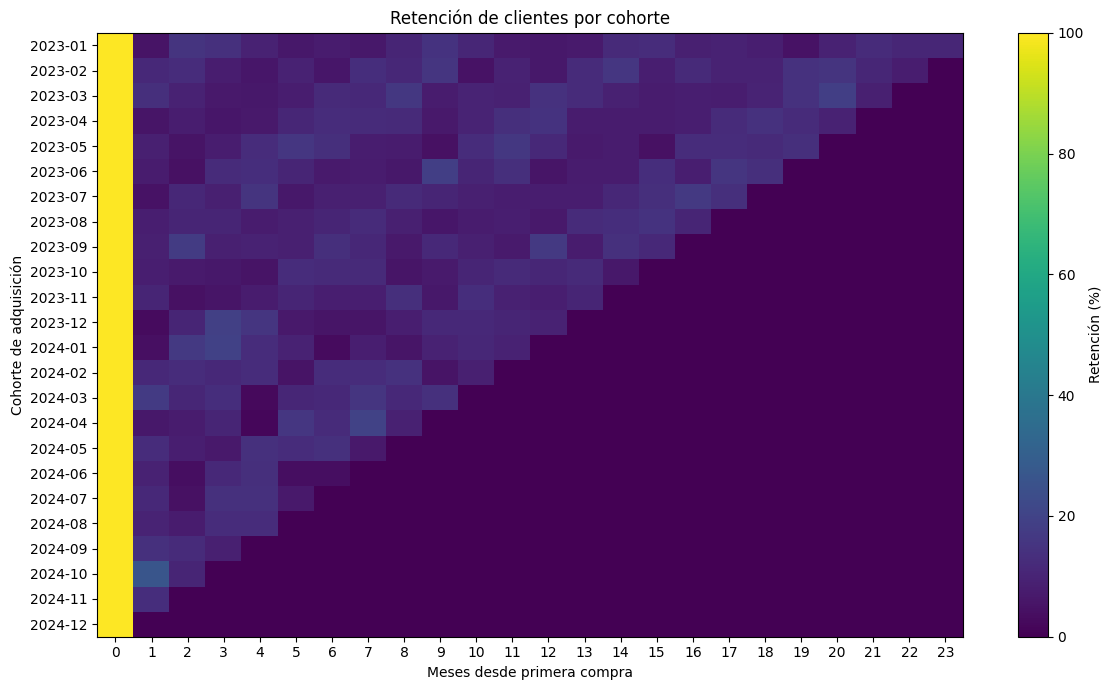

In [160]:
fig, ax = plt.subplots(
    figsize=(12, 7)
)

data_heatmap = (
    retencion_cohortes
    .fillna(0)
    .values
)

image = ax.imshow(
    data_heatmap,
    aspect="auto"
)

ax.set_title(
    "Retención de clientes por cohorte"
)

ax.set_xlabel(
    "Meses desde primera compra"
)

ax.set_ylabel(
    "Cohorte de adquisición"
)

ax.set_xticks(
    range(
        len(retencion_cohortes.columns)
    )
)

ax.set_xticklabels(
    retencion_cohortes.columns
)

ax.set_yticks(
    range(
        len(retencion_cohortes.index)
    )
)

ax.set_yticklabels(
    retencion_cohortes.index.astype(str)
)

plt.colorbar(
    image,
    label="Retención (%)"
)

plt.tight_layout()
plt.show()

### Consideración de negocio

La métrica de retención debe interpretarse dentro del contexto del mercado
inmobiliario.

A diferencia de negocios con compras frecuentes, la adquisición de una
propiedad presenta ciclos de compra considerablemente más largos.

Por ello, una baja recurrencia mensual no implica necesariamente una mala
experiencia del cliente. En este proyecto, la métrica se utiliza principalmente
para identificar compradores recurrentes y patrones de adquisición dentro del
periodo disponible.

Con los siguientes resultados podemos interpretar la recurrencia real del negocio, revisar que la cohorte esté correctamente construida y después pasar a segmentación estadística: canales, ciudades, segmentos de comprador y qué factores están asociados con tickets más altos.

In [161]:
print(
    f"Tasa de recompra: {tasa_recompra:.2f}%"
)

Tasa de recompra: 77.13%


In [162]:
compras_por_cliente[
    "cantidad_compras"
].describe()

count    3139.000000
mean        2.707869
std         1.490689
min         1.000000
25%         2.000000
50%         2.000000
75%         4.000000
max        10.000000
Name: cantidad_compras, dtype: float64

In [163]:
retencion_cohortes.round(2)

indice_cohorte,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohorte,,,,,,,,,,,,,,,,,,,,,
2023-01,100.0,5.19,15.09,13.68,9.43,6.60,7.55,6.60,10.38,14.62,...,11.79,12.74,8.96,9.43,8.49,4.72,9.43,12.26,10.85,10.85
2023-02,100.0,11.45,12.78,7.93,6.17,9.69,6.17,13.22,11.01,15.42,...,15.86,8.37,11.89,9.69,9.69,14.10,14.98,10.57,7.93,NaN
2023-03,100.0,13.31,9.63,6.80,6.52,7.93,11.90,11.61,16.15,7.65,...,9.35,7.65,8.22,7.93,9.92,14.16,18.70,8.78,NaN,NaN
2023-04,100.0,5.78,8.09,6.07,6.94,10.69,12.72,12.14,11.85,6.94,...,7.51,7.51,8.38,12.14,14.16,12.14,9.54,NaN,NaN,NaN
2023-05,100.0,8.70,5.43,8.15,12.50,15.76,13.59,8.15,7.61,4.35,...,7.61,4.35,12.50,12.50,11.96,13.59,NaN,NaN,NaN,NaN
2023-06,100.0,7.74,4.52,12.26,12.90,10.32,7.10,7.74,6.45,18.71,...,7.74,12.90,8.39,15.48,13.55,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,4.69,10.94,8.59,14.84,6.25,8.59,8.59,11.72,10.16,...,10.94,13.28,16.41,13.28,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,8.28,10.34,10.34,7.59,8.97,10.34,12.41,8.97,6.21,...,13.10,14.48,10.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,8.89,17.22,8.89,9.44,8.89,13.33,11.11,6.67,11.67,...,13.89,11.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretación de recurrencia y cohortes

Se identificaron 3,139 clientes únicos, con un promedio de 2.71 compras
por cliente y una mediana de 2 compras.

El 77.13% de los clientes realizó más de una compra dentro del periodo
analizado, lo que indica una presencia considerable de compradores
recurrentes en el dataset.

Sin embargo, esta métrica no debe confundirse con la retención mensual
por cohorte. La tasa de recompra indica si un cliente volvió a comprar
en cualquier momento posterior, mientras que la matriz de cohortes
mide qué proporción realizó una compra en cada mes específico desde
su adquisición.

Los valores NaN de las cohortes más recientes representan periodos que
todavía no son observables y, por lo tanto, no deben interpretarse como
0% de retención.

### 42. Resumir la retención por mes
Ahora podemos obtener una visión general de todas las cohortes:

In [164]:
retencion_promedio_mes = (
    retencion_cohortes
    .mean(axis=0, skipna=True)
)

retencion_promedio_mes

indice_cohorte
0     100.000000
1      10.100949
2       9.580745
3      10.561833
4       9.892863
5       9.433076
6       9.676843
7      10.634745
8       9.936656
9       9.976781
10      9.855174
11     10.287837
12      9.975063
13      9.470150
14     10.404484
15     10.327866
16     10.636439
17     11.494493
18     11.293995
19     11.740778
20     13.161598
21     10.539569
22      9.389286
23     10.849057
dtype: float64

Pero no incluiremos el mes 0, porque siempre es 100%.

In [165]:
retencion_promedio_post_compra = (
    retencion_promedio_mes
    .drop(index=0)
)

retencion_promedio_post_compra

indice_cohorte
1     10.100949
2      9.580745
3     10.561833
4      9.892863
5      9.433076
6      9.676843
7     10.634745
8      9.936656
9      9.976781
10     9.855174
11    10.287837
12     9.975063
13     9.470150
14    10.404484
15    10.327866
16    10.636439
17    11.494493
18    11.293995
19    11.740778
20    13.161598
21    10.539569
22     9.389286
23    10.849057
dtype: float64

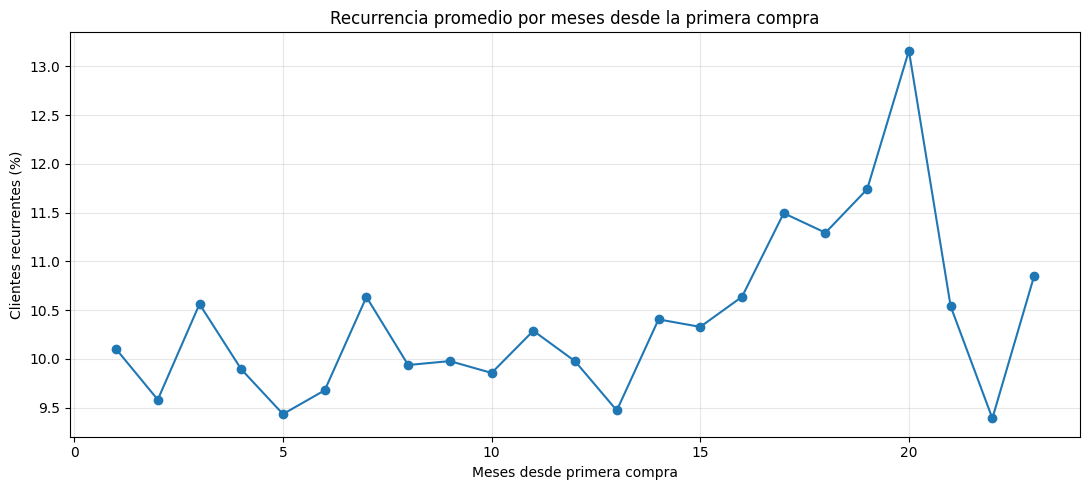

In [166]:
plt.figure(figsize=(11, 5))

plt.plot(
    retencion_promedio_post_compra.index,
    retencion_promedio_post_compra.values,
    marker="o"
)

plt.title(
    "Recurrencia promedio por meses desde la primera compra"
)

plt.xlabel(
    "Meses desde primera compra"
)

plt.ylabel(
    "Clientes recurrentes (%)"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 43. Cuántas cohortes respaldan cada mes
Hay otro detalle estadístico importante. El promedio del mes 1 utiliza casi todas las cohortes, pero el mes 23 solamente puede utilizar las cohortes más antiguas.

In [167]:
cohortes_observadas = (
    retencion_cohortes
    .notna()
    .sum()
)

resumen_retencion = pd.DataFrame({
    "retencion_promedio_pct":
        retencion_promedio_mes,

    "cohortes_observadas":
        cohortes_observadas
})

resumen_retencion

,retencion_promedio_pct,cohortes_observadas
indice_cohorte,,
0,100.000000,24
1,10.100949,23
2,9.580745,22
3,10.561833,21
4,9.892863,20
5,9.433076,19
6,9.676843,18
7,10.634745,17
8,9.936656,16


### 44. Ahora comparemos recurrencia por segmento de cliente
Aquí ya podemos conectar cohortes con dim_clientes.

Primero agrega a cada cliente su número de compras:

In [168]:
clientes_comportamiento = (
    compras_por_cliente
    .reset_index()
    .merge(
        clientes[
            [
                "id_cliente",
                "segmento_comprador",
                "ciudad",
                "pais"
            ]
        ],
        on="id_cliente",
        how="left"
    )
)

Creamos una bandera:

In [169]:
clientes_comportamiento["es_recurrente"] = (
    clientes_comportamiento["cantidad_compras"] > 1
)

Y analizamos por segmento:

In [170]:
recurrencia_segmento = (
    clientes_comportamiento
    .groupby("segmento_comprador")
    .agg(
        clientes=("id_cliente", "nunique"),
        clientes_recurrentes=(
            "es_recurrente",
            "sum"
        ),
        compras_promedio=(
            "cantidad_compras",
            "mean"
        ),
        gasto_promedio=(
            "gasto_total",
            "mean"
        )
    )
)

Ahora calculamos:
\[
TasaRecompra_s =
\frac{ClientesRecurrentes_s}
{Clientes_s}
\times100
\]

In [171]:
recurrencia_segmento[
    "tasa_recompra_pct"
] = (
    recurrencia_segmento[
        "clientes_recurrentes"
    ]
    / recurrencia_segmento["clientes"]
    * 100
)

recurrencia_segmento.sort_values(
    "tasa_recompra_pct",
    ascending=False
)

,clientes,clientes_recurrentes,compras_promedio,gasto_promedio,tasa_recompra_pct
segmento_comprador,,,,,
Primera vez,1770,1454,2.995480,2.137616e+06,82.146893
Alto patrimonio,455,339,2.428571,1.664785e+06,74.505495
Inversionista,914,628,2.289934,1.609896e+06,68.708972


## ¿El segmento del comprador está asociado con la probabilidad de volver a comprar?

### 45. Recurrencia por segmento
Ya tenemos clientes_comportamiento, así que primero construimos el resumen:

In [172]:
recurrencia_segmento = (
    clientes_comportamiento
    .groupby("segmento_comprador")
    .agg(
        clientes=("id_cliente", "nunique"),
        clientes_recurrentes=("es_recurrente", "sum"),
        compras_promedio=("cantidad_compras", "mean"),
        gasto_promedio=("gasto_total", "mean"),
        ticket_promedio=("ticket_promedio", "mean")
    )
)

recurrencia_segmento["tasa_recompra_pct"] = (
    recurrencia_segmento["clientes_recurrentes"]
    / recurrencia_segmento["clientes"]
    * 100
)

recurrencia_segmento.sort_values(
    "tasa_recompra_pct",
    ascending=False
)

,clientes,clientes_recurrentes,compras_promedio,gasto_promedio,ticket_promedio,tasa_recompra_pct
segmento_comprador,,,,,,
Primera vez,1770,1454,2.995480,2.137616e+06,713987.776584,82.146893
Alto patrimonio,455,339,2.428571,1.664785e+06,689287.284783,74.505495
Inversionista,914,628,2.289934,1.609896e+06,701107.658317,68.708972


Aquí todavía estamos haciendo estadística descriptiva.

### 46. Visualizar la tasa de recompra

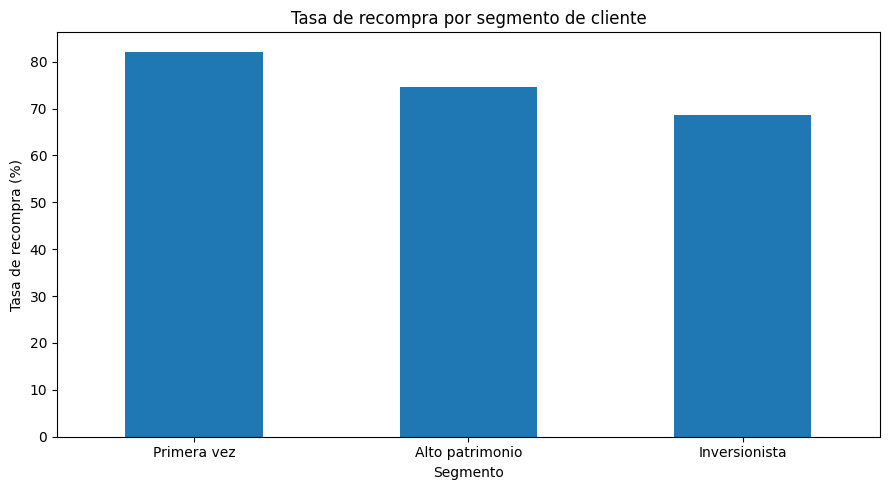

In [173]:
plot_segmentos = (
    recurrencia_segmento["tasa_recompra_pct"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plot_segmentos.plot(
    kind="bar"
)

plt.title(
    "Tasa de recompra por segmento de cliente"
)

plt.xlabel("Segmento")
plt.ylabel("Tasa de recompra (%)")

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

### Pregunta analítica

A primera vista pueden existir diferencias en la tasa de recompra entre
los diferentes perfiles de cliente.

Sin embargo, observar porcentajes distintos no es suficiente para concluir
que el segmento está relacionado con la recurrencia.

Para evaluar esta relación se realizará una prueba estadística de
independencia.

## 47. Prueba Chi-cuadrado de independencia

Se busca evaluar si existe asociación estadística entre el segmento
del comprador y su comportamiento de recompra.

### Hipótesis

$$
H_0:
\text{El segmento del comprador y la recurrencia son independientes}
$$

$$
H_1:
\text{Existe asociación entre el segmento del comprador y la recurrencia}
$$

Se utilizará un nivel de significancia:

$$
\alpha = 0.05
$$

In [176]:
from scipy.stats import chi2_contingency

In [177]:
tabla_segmento_recompra = pd.crosstab(
    clientes_comportamiento["segmento_comprador"],
    clientes_comportamiento["es_recurrente"]
)

tabla_segmento_recompra

es_recurrente,False,True
segmento_comprador,,
Alto patrimonio,116,339
Inversionista,286,628
Primera vez,316,1454


In [178]:
chi2, p_value, dof, expected = chi2_contingency(
    tabla_segmento_recompra
)

print(f"Chi-cuadrado: {chi2:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Grados de libertad: {dof}")

Chi-cuadrado: 63.7692
p-value: 0.000000
Grados de libertad: 2


### 48. Interpretación automática

In [179]:
alpha = 0.05

if p_value < alpha:
    print(
        "Se rechaza H0: existe evidencia de asociación "
        "entre segmento y recurrencia."
    )
else:
    print(
        "No se rechaza H0: no existe evidencia suficiente "
        "de asociación entre segmento y recurrencia."
    )

Se rechaza H0: existe evidencia de asociación entre segmento y recurrencia.


### 49. Revisar los valores esperados
Chi-cuadrado tiene un supuesto importante: las frecuencias esperadas no deberían ser demasiado pequeñas.

In [180]:
expected_df = pd.DataFrame(
    expected,
    index=tabla_segmento_recompra.index,
    columns=tabla_segmento_recompra.columns
)

expected_df

es_recurrente,False,True
segmento_comprador,,
Alto patrimonio,104.074546,350.925454
Inversionista,209.064033,704.935967
Primera vez,404.861421,1365.138579


In [181]:
(expected_df < 5).sum().sum()

np.int64(0)

Idealmente obtenemos: 0

Con más de 3,000 clientes probablemente no tendremos problemas.

### 50. Tamaño del efecto: Cramér's V
Aquí viene algo importante.

El p-value responde:
¿Existe evidencia de asociación?

Pero no nos dice qué tan fuerte es.

Para eso usamos Cramér's V:
\[
V =
\sqrt{
\frac{\chi^2}
{n(k-1)}
}
\]
donde:
- \(\chi^2\) = estadístico Chi-cuadrado
- \(n\) = número de observaciones
- \(k\) = menor dimensión de la tabla

In [182]:
n = tabla_segmento_recompra.to_numpy().sum()

min_dim = min(
    tabla_segmento_recompra.shape
) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dim)
)

print(
    f"Cramér's V: {cramers_v:.4f}"
)

Cramér's V: 0.1425


Como orientación general:

V ≈ 0.10 → asociación débil

V ≈ 0.30 → asociación moderada

V ≈ 0.50 → asociación fuerte

No los tomes como límites universales, pero sirven como referencia.

###51. ¿Los segmentos compran diferente cantidad de propiedades?

Ahora la variable cambia:

segmento_comprador → categórica

cantidad_compras → numérica discreta

Podemos visualizar primero:

In [183]:
segmentos_disponibles = (
    clientes_comportamiento[
        "segmento_comprador"
    ]
    .dropna()
    .unique()
)

for segmento in segmentos_disponibles:

    datos = clientes_comportamiento.loc[
        clientes_comportamiento[
            "segmento_comprador"
        ] == segmento,
        "cantidad_compras"
    ]

    print(
        segmento,
        datos.describe()
    )

    print()

Primera vez count    1770.000000
mean        2.995480
std         1.586753
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        10.000000
Name: cantidad_compras, dtype: float64

Inversionista count    914.000000
mean       2.289934
std        1.263771
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       10.000000
Name: cantidad_compras, dtype: float64

Alto patrimonio count    455.000000
mean       2.428571
std        1.258827
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        8.000000
Name: cantidad_compras, dtype: float64



Y con boxplot:

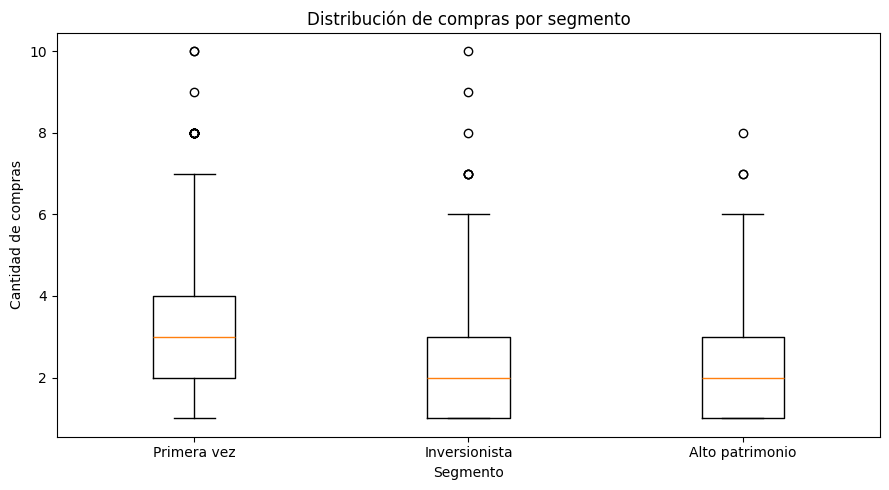

In [184]:
grupos = [
    clientes_comportamiento.loc[
        clientes_comportamiento["segmento_comprador"] == segmento,
        "cantidad_compras"
    ].values
    for segmento in segmentos_disponibles
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    grupos,
    tick_labels=segmentos_disponibles
)

plt.title(
    "Distribución de compras por segmento"
)

plt.xlabel("Segmento")
plt.ylabel("Cantidad de compras")

plt.tight_layout()
plt.show()

### 52. Kruskal-Wallis
Como cantidad_compras toma valores como:
1
2
3
4
...
10

y probablemente no sigue una distribución normal, podemos usar Kruskal-Wallis.

Hipótesis:
\[
H_0:
\text{las distribuciones son iguales entre segmentos}
\]
\[
H_1:
\text{al menos un segmento presenta una distribución diferente}
\]
Código:

In [185]:
from scipy.stats import kruskal

grupos_compras = [
    clientes_comportamiento.loc[
        clientes_comportamiento["segmento_comprador"] == segmento,
        "cantidad_compras"
    ]
    for segmento in segmentos_disponibles
]

h_stat, p_kruskal = kruskal(
    *grupos_compras
)

print(
    f"Kruskal-Wallis H: {h_stat:.4f}"
)

print(
    f"p-value: {p_kruskal:.6f}"
)

Kruskal-Wallis H: 147.4485
p-value: 0.000000


Interpretación:

In [186]:
if p_kruskal < 0.05:
    print(
        "Existen diferencias estadísticamente significativas "
        "en la cantidad de compras entre los segmentos."
    )
else:
    print(
        "No existe evidencia suficiente para afirmar que "
        "la cantidad de compras difiere entre segmentos."
    )

Existen diferencias estadísticamente significativas en la cantidad de compras entre los segmentos.


Pero hay una precaución:

Si sale significativo, Kruskal-Wallis solo dice:
al menos uno es diferente.

No dice cuál.

Para saber:
Inversionista vs Primera vez
Inversionista vs Alto patrimonio
Primera vez vs Alto patrimonio

necesitaríamos comparaciones posteriores —por ejemplo Mann–Whitney por pares con corrección de Holm, que ya conoces del proyecto anterior.

## Conclusiones

El análisis permitió construir y validar un flujo completo de preparación y exploración de los datos de ventas inmobiliarias antes de su utilización en el dashboard.

### Calidad y preparación de los datos

Se revisaron las tablas de clientes, propiedades y ventas para validar tipos de datos, valores nulos, duplicados, claves principales y relaciones entre tablas.

También se comprobó la consistencia entre atributos repetidos en la tabla de ventas y la dimensión de propiedades. A partir de esta validación se propuso una estructura más normalizada, manteniendo en la tabla de hechos principalmente las métricas transaccionales y utilizando las dimensiones para recuperar las características descriptivas de clientes y propiedades.

Las validaciones realizadas no mostraron problemas que justificaran la eliminación masiva de registros.

### Validación de valores extremos

El método IQR permitió identificar posibles valores atípicos en algunas variables. Sin embargo, estos registros no fueron eliminados automáticamente.

La diferencia absoluta entre el precio publicado y el precio de venta presentó valores extremos, mientras que la variación porcentual entre ambos precios no mostró outliers. Esto sugiere que las diferencias absolutas elevadas están principalmente relacionadas con propiedades de mayor valor.

En el precio de venta por metro cuadrado también se identificaron valores estadísticamente extremos, pero estos pueden estar asociados con características legítimas del mercado como ubicación, tamaño y tipo de propiedad.

Las diferencias encontradas entre la comisión registrada y la comisión recalculada fueron pequeñas en términos relativos, por lo que se consideran compatibles con efectos de redondeo o precisión decimal.

Por lo tanto, se decidió conservar los valores extremos siempre que fueran consistentes con las reglas de negocio.

### Validación de indicadores comerciales

Los principales KPIs calculados en Python coincidieron con los resultados obtenidos previamente en Power BI:

- Ingreso total.
- Cantidad de ventas.
- Ticket promedio.
- Comisión total.

Esta coincidencia funciona como una validación cruzada de la preparación de los datos y de las reglas utilizadas para calcular los indicadores del negocio.

### Comportamiento de clientes

Se identificaron **3,139 clientes únicos**, con un promedio de aproximadamente **2.71 compras por cliente** y una mediana de **2 compras**.

La tasa de recompra dentro del periodo analizado fue de **77.13%**, lo que muestra una presencia considerable de compradores recurrentes dentro del dataset.

El análisis de cohortes permitió estudiar el comportamiento de los clientes según el mes de su primera compra. Los resultados muestran que la recurrencia varía entre cohortes y entre los distintos meses posteriores a la adquisición.

Debido a la naturaleza del mercado inmobiliario, estas métricas deben interpretarse como recurrencia transaccional dentro del periodo disponible y no como retención tradicional de un negocio de compras frecuentes.

### Segmentación de clientes

Se observaron diferencias descriptivas entre los segmentos de compradores.

La tasa de recompra fue aproximadamente:

- **Primera vez:** 82.15%
- **Alto patrimonio:** 74.51%
- **Inversionista:** 68.71%

La prueba Chi-cuadrado encontró evidencia estadísticamente significativa de asociación entre el segmento del comprador y la recurrencia ($p < 0.001$).

Sin embargo, el tamaño del efecto obtenido mediante Cramér's V fue de **0.1425**, indicando que la asociación es relativamente débil. Por lo tanto, aunque el segmento está relacionado con la recompra, no parece explicar por sí solo una parte importante del comportamiento recurrente.

También se analizaron las diferencias en la cantidad de compras mediante la prueba de Kruskal-Wallis.

El resultado fue estadísticamente significativo:

$$
H = 147.4485,\quad p < 0.001
$$

Esto proporciona evidencia de que al menos uno de los segmentos presenta una distribución de cantidad de compras diferente a los demás.

Sin embargo, esta prueba no identifica qué segmentos específicos presentan esas diferencias.

## Conclusión general

Los datos presentan una estructura consistente y suficiente calidad para ser utilizados en el análisis comercial y en la construcción del dashboard interactivo.

El análisis muestra diferencias en recurrencia, frecuencia de compra y comportamiento entre segmentos de clientes, además de patrones relacionados con precios, ubicaciones, canales de venta y cohortes.

Los

In [190]:
from pathlib import Path

processed_path = Path("../data/processed")
public_path = Path("../public/data/processed")

processed_path.mkdir(parents=True, exist_ok=True)
public_path.mkdir(parents=True, exist_ok=True)

In [191]:
clientes.to_csv(
    processed_path / "dim_clientes_clean.csv",
    index=False
)

propiedades.to_csv(
    processed_path / "dim_propiedades_clean.csv",
    index=False
)

ventas_normalizadas.to_csv(
    processed_path / "hechos_ventas_propiedades_clean.csv",
    index=False
)

print("Archivos clean exportados correctamente.")

Archivos clean exportados correctamente.
